# General

In [ ]:
import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

DATA_ROOT = Path(os.environ.get('DL_DATA_DIR', '../../.lab-data')).resolve()
import sys
sys.path.insert(0, str(Path('../lab8').resolve()))
from model_io import save_bundle, load_bundle
SIZE = 150

# Data

In [3]:
train_dir = DATA_ROOT / 'cats-dogs' / 'train'
validation_dir = DATA_ROOT / 'cats-dogs' / 'validation'
test_dir = DATA_ROOT / 'cats-dogs' / 'test'
classes = ['cat', 'dog']
split = pd.read_csv('../lab7/split.csv')
display(pd.crosstab(split['subset'], split['class']))

class,cat,dog
subset,,
test,500,500
train,1000,1000
validation,500,500


# VGG16

## Data

In [ ]:
NAME = 'vgg16'
preprocess_input = keras.applications.vgg16.preprocess_input

In [ ]:
def make_generators(preprocess_input):
    generators = []
    for directory in [train_dir, validation_dir, test_dir]:
        generator = ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_directory(
            directory, target_size=(SIZE, SIZE), batch_size=25,
            classes=classes, class_mode='binary', shuffle=False)
        generators.append(generator)
    return generators

In [4]:
train_generator, validation_generator, test_generator = make_generators(preprocess_input)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


## Model

In [5]:
# Start the head search from the same frozen ImageNet features as lab 8.
base = keras.applications.VGG16(
    weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3), pooling='avg')
base.trainable = False

In [ ]:
def build_head(input_shape, units=128, dropout=0.5, extra_units=0, optimizer='adam', learning_rate=0.001):
    head = keras.Sequential([layers.Input(shape=input_shape),
                             layers.Dense(units, activation='relu'), layers.Dropout(dropout)])
    if extra_units:
        head.add(layers.Dense(extra_units, activation='relu'))
    head.add(layers.Dense(1, activation='sigmoid'))
    opt = keras.optimizers.get(optimizer)
    opt.learning_rate = learning_rate
    head.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return head

In [6]:
# Reuse the frozen features computed in lab 8.
cache = DATA_ROOT / 'features' / f'{NAME}_{SIZE}'
features = {subset: np.load(cache / f'{subset}.npy') for subset in ['train', 'validation']}
labels = {'train': train_generator.classes.astype('float32'),
          'validation': validation_generator.classes.astype('float32')}
for subset in features:
    print(subset, features[subset].shape)

train (2000, 512)
validation (1000, 512)


## Head training

In [ ]:
def plot_history(history, name):
    history = pd.DataFrame(history)
    epochs = np.arange(1, len(history) + 1)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axs, ['accuracy', 'loss']):
        ax.plot(epochs, history[metric], label='Training')
        if f'val_{metric}' in history:
            ax.plot(epochs, history[f'val_{metric}'], label='Validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(metric.capitalize())
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    fig.savefig(f'results/{name}_history.png', dpi=150)
    plt.show()

In [ ]:
def train_heads(features, labels, configs, model_name):
    results = []
    for config in configs:
        keras.utils.set_random_seed(42)
        name = config['name']
        head = build_head(features['train'].shape[1:], **{k: v for k, v in config.items() if k not in ['name', 'epochs', 'batch_size']})
        start = time.perf_counter()
        history = head.fit(
            features['train'], labels['train'],
            validation_data=(features['validation'], labels['validation']),
            epochs=config['epochs'], batch_size=config['batch_size'], verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])
        val_loss, val_accuracy = head.evaluate(features['validation'], labels['validation'], verbose=0)
        head.save(head_dir / f'{model_name}_{name}.keras')
        results.append({**config, 'epochs_run': len(history.epoch),
                        'best_epoch': int(np.argmin(history.history['val_loss']) + 1),
                        'seconds': time.perf_counter() - start, 'val_loss': val_loss,
                        'val_accuracy': val_accuracy,
                        'train_accuracy': history.history['accuracy'][-1]})
        pd.DataFrame(history.history).to_csv(f'results/{model_name}_head_{name}_history.csv', index=False)
        print(name, f'Validation: {val_accuracy:.2%}, loss: {val_loss:.4f}')
        plot_history(history.history, f'{model_name}_head_{name}')
    results = pd.DataFrame(results)
    display(results)
    return results

In [ ]:
head_dir = DATA_ROOT / 'models' / 'lab9' / 'heads'
results = []
head_configs = {}

### Reference

reference Validation: 97.00%, loss: 0.0916


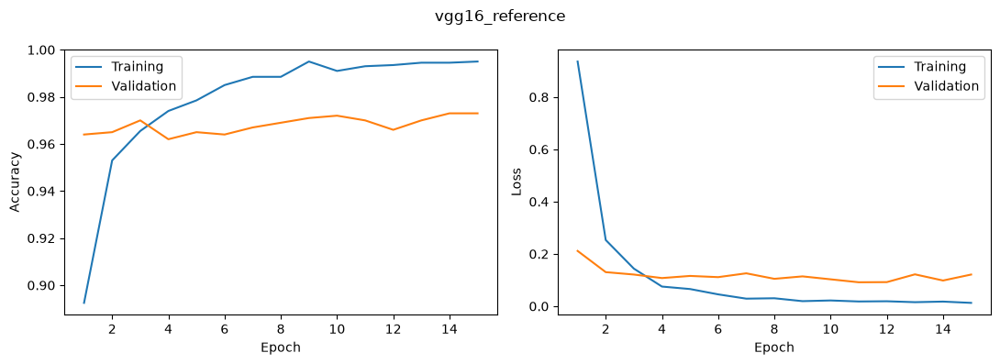

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,reference,128,0.5,0,adam,0.001,15,25,15,11,7.138778,0.091584,0.97,0.995


In [10]:
head_configs['Reference'] = [
    {'name': 'reference', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25}
]
results.append(train_heads(features, labels, head_configs['Reference'], NAME))

### Dense width

units_32 Validation: 96.30%, loss: 0.0847


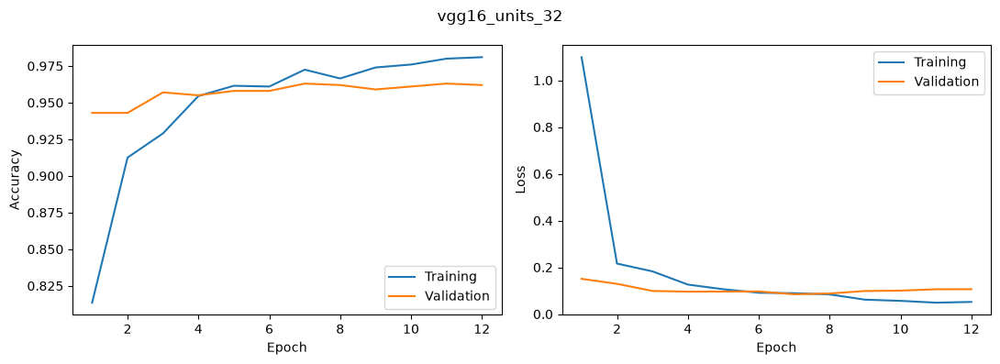

units_256 Validation: 97.00%, loss: 0.1153


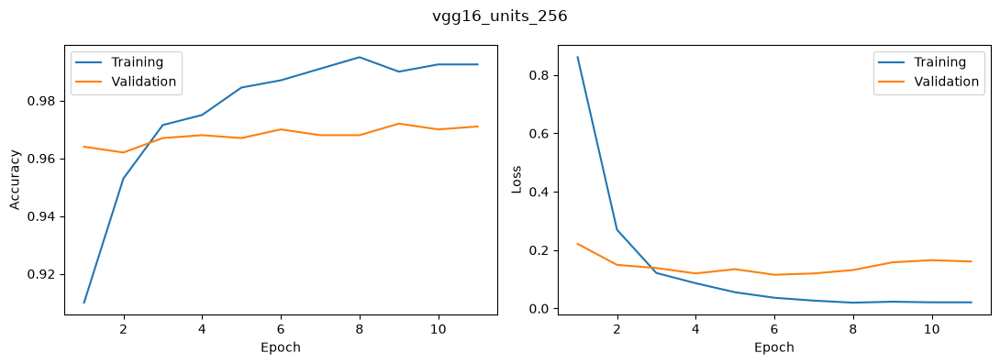

units_512 Validation: 96.50%, loss: 0.1798


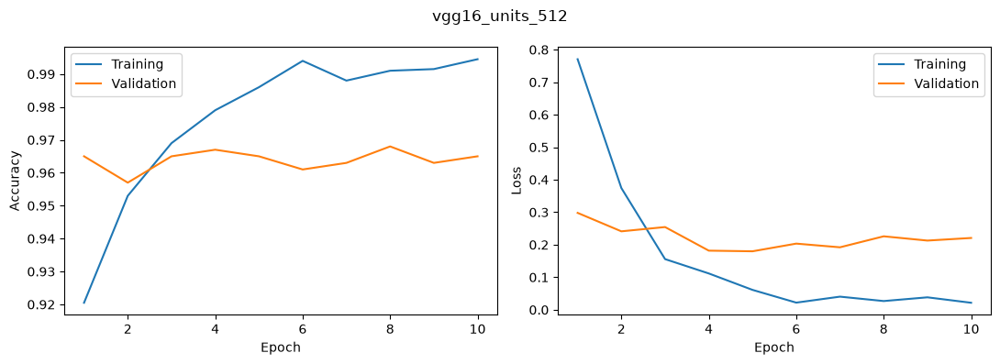

units_1024 Validation: 96.80%, loss: 0.3093


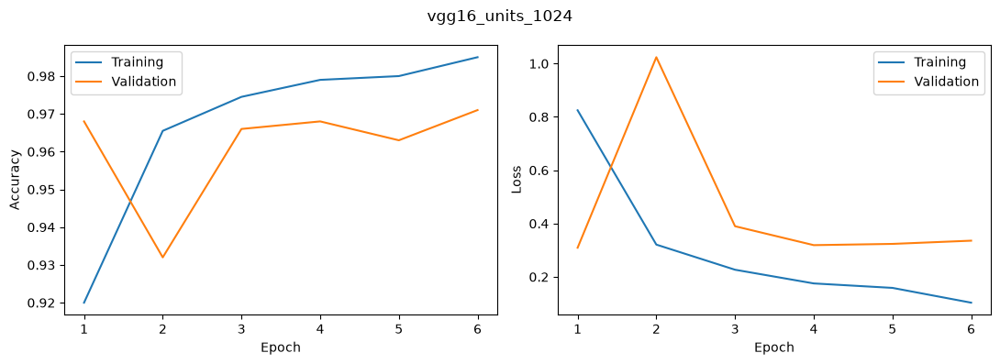

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
1,units_32,32,0.5,0,adam,0.001,15,25,12,7,6.079728,0.084660,0.963,0.9810
2,units_256,256,0.5,0,adam,0.001,15,25,11,6,5.161528,0.115302,0.970,0.9925
3,units_512,512,0.5,0,adam,0.001,15,25,10,5,5.189735,0.179827,0.965,0.9945
4,units_1024,1024,0.5,0,adam,0.001,15,25,6,1,4.039514,0.309327,0.968,0.9850


In [10]:
head_configs['Dense width'] = [
    {'name': 'units_32', 'units': 32, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'units_256', 'units': 256, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'units_512', 'units': 512, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'units_1024', 'units': 1024, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25}
]
results.append(train_heads(features, labels, head_configs['Dense width'], NAME))

### Dropout

dropout_0.25 Validation: 95.70%, loss: 0.1589


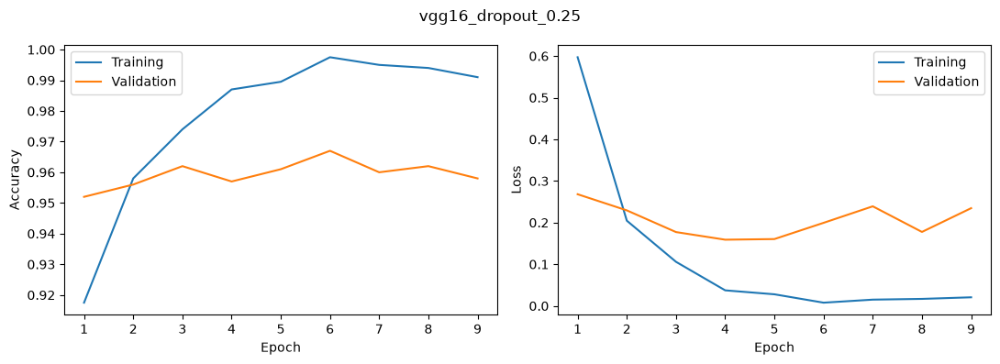

dropout_0.6 Validation: 96.80%, loss: 0.0877


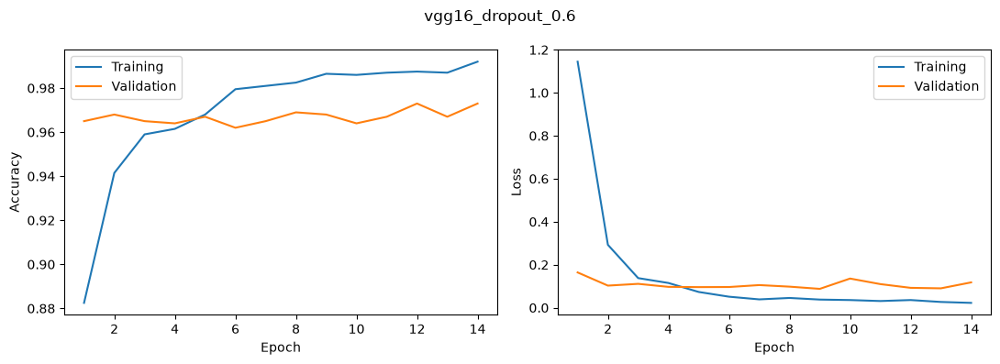

dropout_0.8 Validation: 96.70%, loss: 0.0696


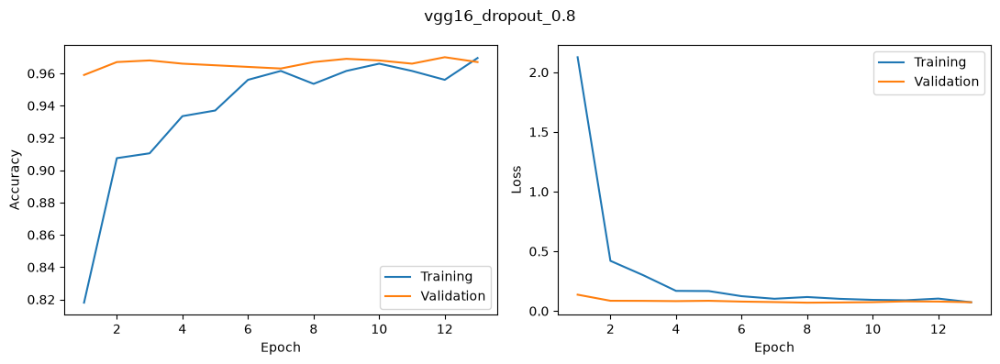

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
5,dropout_0.25,128,0.25,0,adam,0.001,15,25,9,4,4.153173,0.158931,0.957,0.9910
6,dropout_0.6,128,0.60,0,adam,0.001,15,25,14,9,5.800601,0.087713,0.968,0.9920
7,dropout_0.8,128,0.80,0,adam,0.001,15,25,13,8,5.276031,0.069597,0.967,0.9695


In [10]:
head_configs['Dropout'] = [
    {'name': 'dropout_0.25', 'units': 128, 'dropout': 0.25, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'dropout_0.6', 'units': 128, 'dropout': 0.6, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'dropout_0.8', 'units': 128, 'dropout': 0.8, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25}
]
results.append(train_heads(features, labels, head_configs['Dropout'], NAME))

### Extra Dense layer

extra_32 Validation: 97.00%, loss: 0.0858


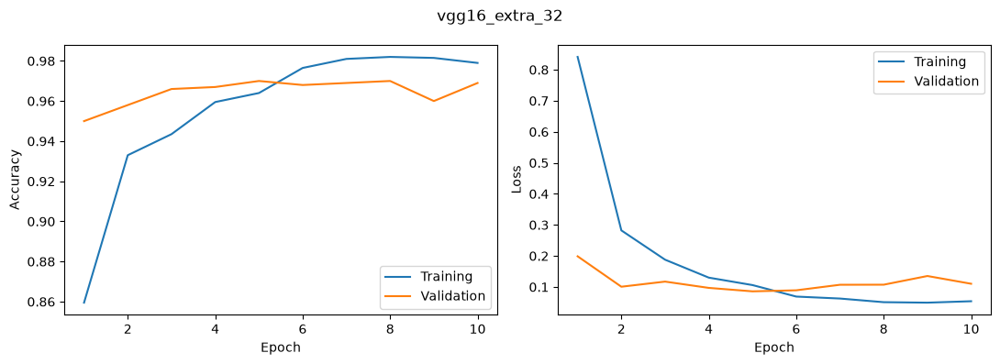

extra_128 Validation: 96.80%, loss: 0.0957


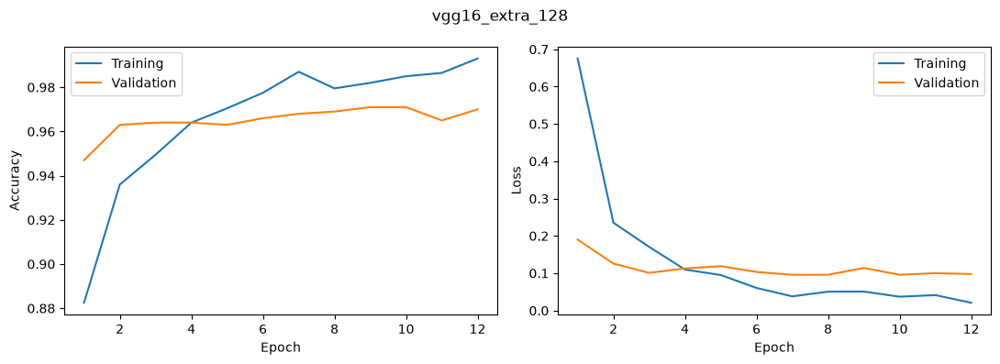

extra_256 Validation: 96.70%, loss: 0.0759


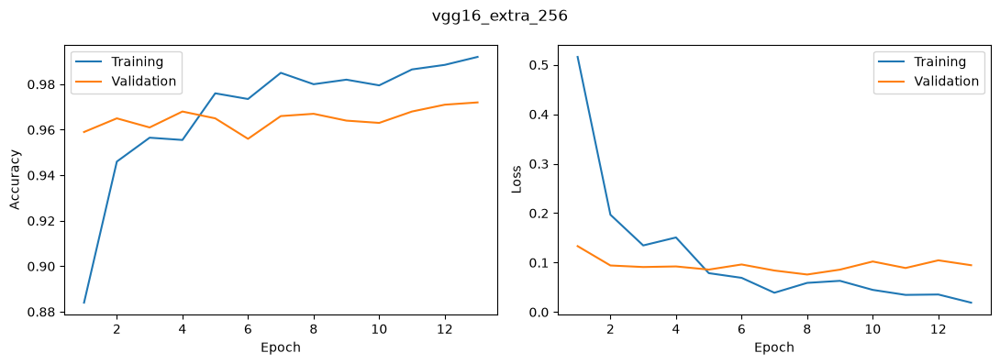

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
8,extra_32,128,0.5,32,adam,0.001,15,25,10,5,5.111114,0.085823,0.970,0.979
9,extra_128,128,0.5,128,adam,0.001,15,25,12,7,5.626695,0.095702,0.968,0.993
10,extra_256,128,0.5,256,adam,0.001,15,25,13,8,5.913367,0.075863,0.967,0.992


In [10]:
head_configs['Extra Dense layer'] = [
    {'name': 'extra_32', 'units': 128, 'dropout': 0.5, 'extra_units': 32, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'extra_128', 'units': 128, 'dropout': 0.5, 'extra_units': 128, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'extra_256', 'units': 128, 'dropout': 0.5, 'extra_units': 256, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25}
]
results.append(train_heads(features, labels, head_configs['Extra Dense layer'], NAME))

### Epochs

epochs_5 Validation: 96.20%, loss: 0.1077


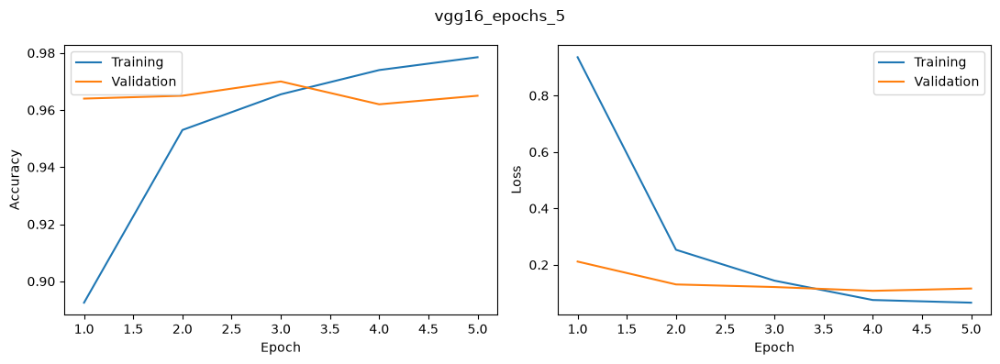

epochs_10 Validation: 97.20%, loss: 0.1029


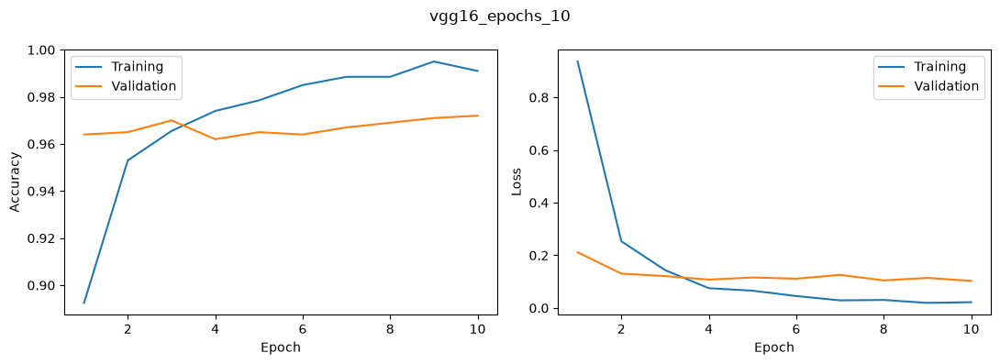

epochs_20 Validation: 97.00%, loss: 0.0916


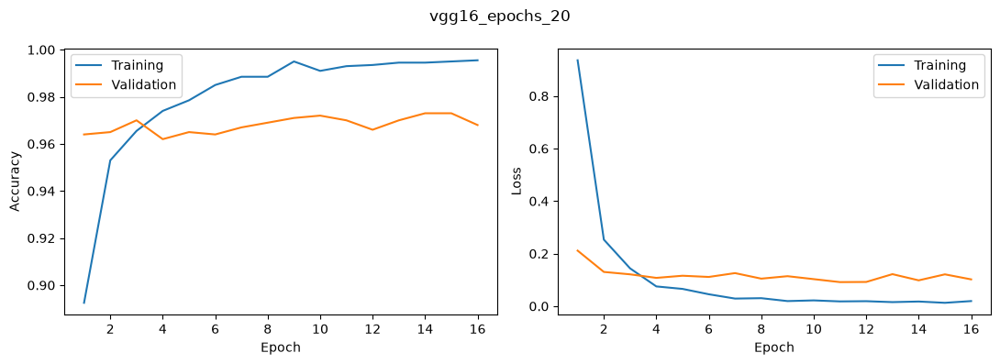

epochs_25 Validation: 97.00%, loss: 0.0916


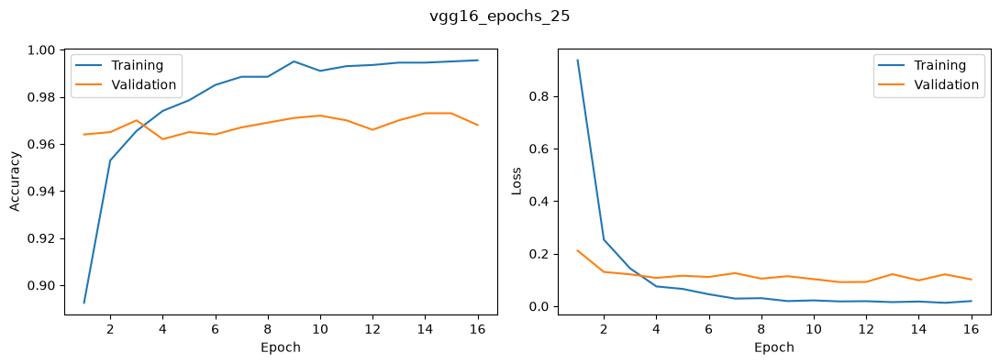

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
11,epochs_5,128,0.5,0,adam,0.001,5,25,5,4,3.238112,0.107670,0.962,0.9785
12,epochs_10,128,0.5,0,adam,0.001,10,25,10,10,4.614399,0.102871,0.972,0.9910
13,epochs_20,128,0.5,0,adam,0.001,20,25,16,11,6.087835,0.091584,0.970,0.9955
14,epochs_25,128,0.5,0,adam,0.001,25,25,16,11,6.171728,0.091584,0.970,0.9955


In [10]:
head_configs['Epochs'] = [
    {'name': 'epochs_5', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 5, 'batch_size': 25},
    {'name': 'epochs_10', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 10, 'batch_size': 25},
    {'name': 'epochs_20', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 20, 'batch_size': 25},
    {'name': 'epochs_25', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 25, 'batch_size': 25}
]
results.append(train_heads(features, labels, head_configs['Epochs'], NAME))

### Batch size

batch_50 Validation: 97.30%, loss: 0.0976


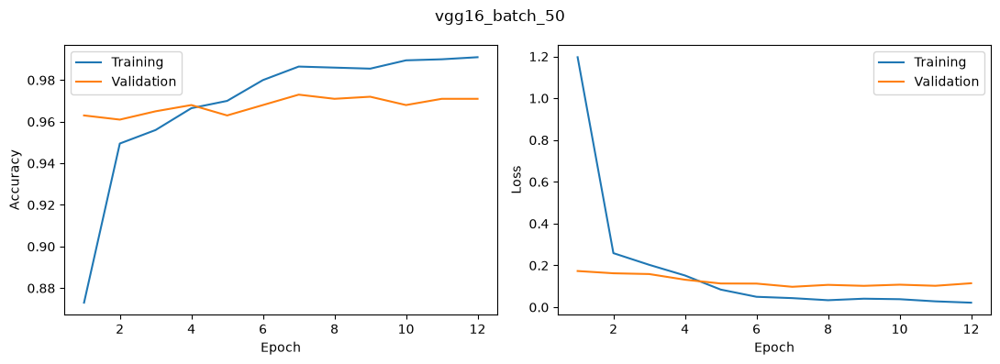

batch_100 Validation: 96.50%, loss: 0.1087


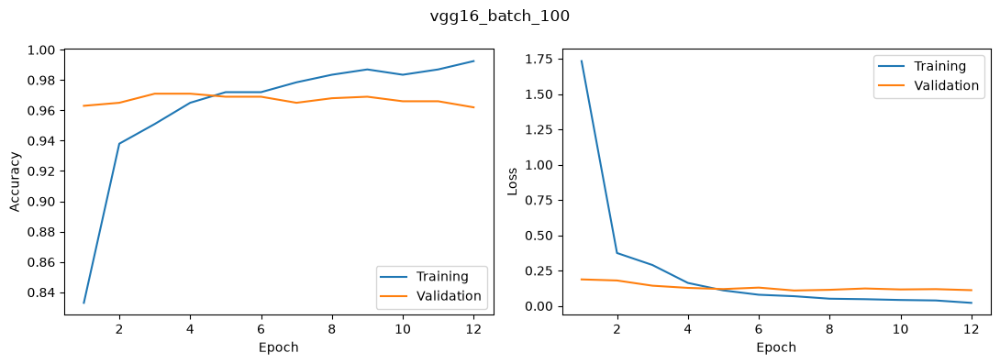

batch_125 Validation: 96.90%, loss: 0.1115


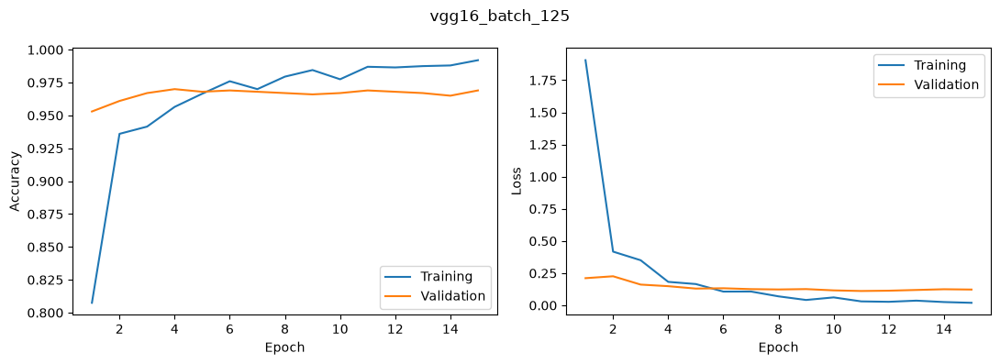

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
15,batch_50,128,0.5,0,adam,0.001,15,50,12,7,4.760751,0.097642,0.973,0.9910
16,batch_100,128,0.5,0,adam,0.001,15,100,12,7,4.053351,0.108747,0.965,0.9925
17,batch_125,128,0.5,0,adam,0.001,15,125,15,11,4.213220,0.111518,0.969,0.9920


In [10]:
head_configs['Batch size'] = [
    {'name': 'batch_50', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 50},
    {'name': 'batch_100', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 100},
    {'name': 'batch_125', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 125}
]
results.append(train_heads(features, labels, head_configs['Batch size'], NAME))

### Optimizer

sgd Validation: 96.70%, loss: 0.0953


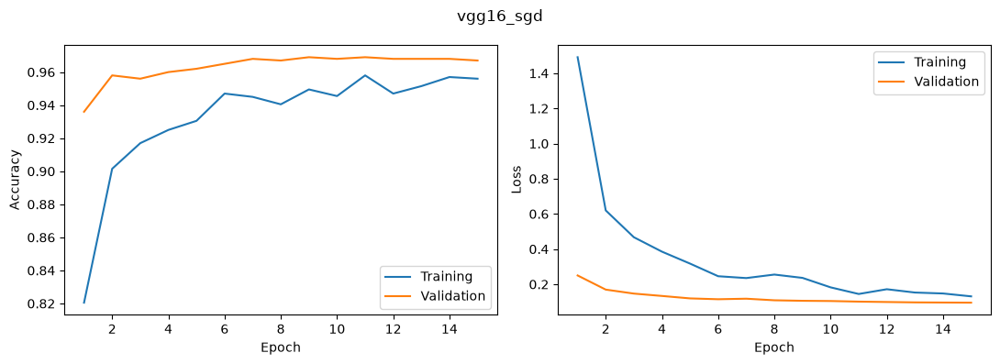

rmsprop Validation: 96.70%, loss: 0.1206


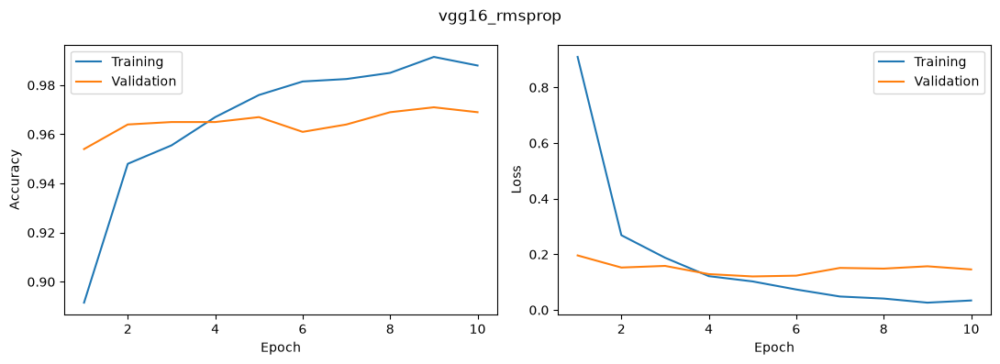

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
18,sgd,128,0.5,0,sgd,0.001,15,25,15,15,5.448636,0.095295,0.967,0.956
19,rmsprop,128,0.5,0,rmsprop,0.001,15,25,10,5,4.408455,0.120603,0.967,0.988


In [10]:
head_configs['Optimizer'] = [
    {'name': 'sgd', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'sgd', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25},
    {'name': 'rmsprop', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'rmsprop', 'learning_rate': 0.001, 'epochs': 15, 'batch_size': 25}
]
results.append(train_heads(features, labels, head_configs['Optimizer'], NAME))

### Learning rate

lr_0.0001 Validation: 96.40%, loss: 0.1370


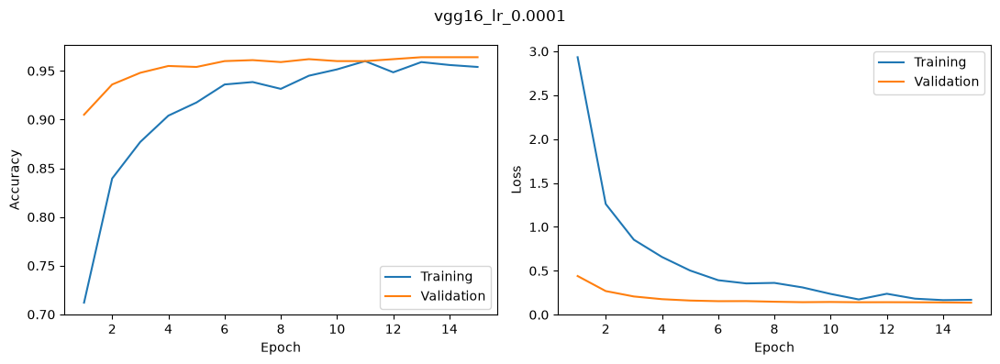

lr_1e-05 Validation: 92.00%, loss: 0.3427


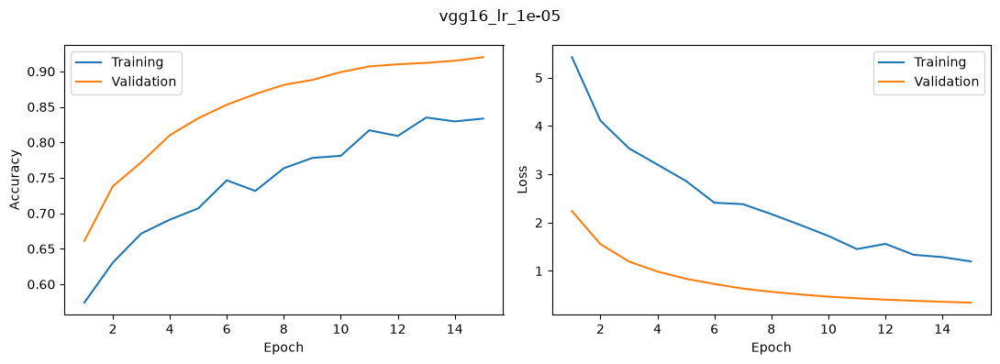

lr_1e-06 Validation: 70.10%, loss: 1.8195


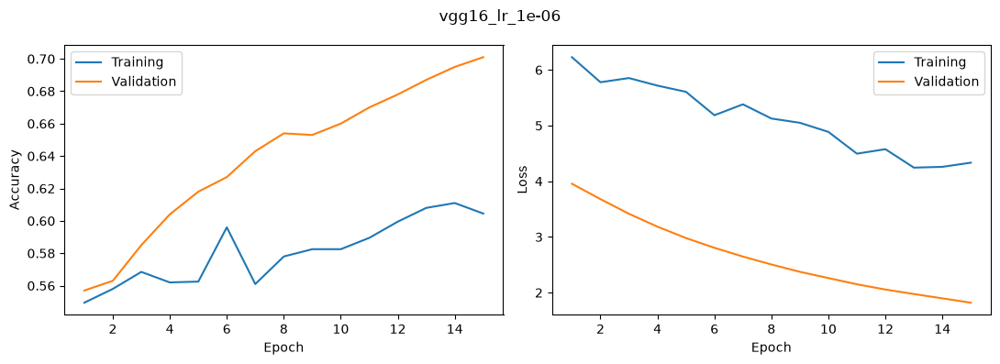

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
20,lr_0.0001,128,0.5,0,adam,0.000100,15,25,15,15,5.869326,0.137008,0.964,0.9540
21,lr_1e-05,128,0.5,0,adam,0.000010,15,25,15,15,5.835927,0.342670,0.920,0.8335
22,lr_1e-06,128,0.5,0,adam,0.000001,15,25,15,15,5.876328,1.819476,0.701,0.6045


In [10]:
head_configs['Learning rate'] = [
    {'name': 'lr_0.0001', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 0.0001, 'epochs': 15, 'batch_size': 25},
    {'name': 'lr_1e-05', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 1e-05, 'epochs': 15, 'batch_size': 25},
    {'name': 'lr_1e-06', 'units': 128, 'dropout': 0.5, 'extra_units': 0, 'optimizer': 'adam', 'learning_rate': 1e-06, 'epochs': 15, 'batch_size': 25}
]
results.append(train_heads(features, labels, head_configs['Learning rate'], NAME))

In [10]:
results = pd.concat(results, ignore_index=True)
results.to_csv(f'results/{NAME}_experiments.csv', index=False)
display(results)

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,reference,128,0.50,0,adam,0.001000,15,25,15,11,7.138778,0.091584,0.970,0.9950
1,units_32,32,0.50,0,adam,0.001000,15,25,12,7,6.079728,0.084660,0.963,0.9810
2,units_256,256,0.50,0,adam,0.001000,15,25,11,6,5.161528,0.115302,0.970,0.9925
3,units_512,512,0.50,0,adam,0.001000,15,25,10,5,5.189735,0.179827,0.965,0.9945
4,units_1024,1024,0.50,0,adam,0.001000,15,25,6,1,4.039514,0.309327,0.968,0.9850
5,dropout_0.25,128,0.25,0,adam,0.001000,15,25,9,4,4.153173,0.158931,0.957,0.9910
6,dropout_0.6,128,0.60,0,adam,0.001000,15,25,14,9,5.800601,0.087713,0.968,0.9920
7,dropout_0.8,128,0.80,0,adam,0.001000,15,25,13,8,5.276031,0.069597,0.967,0.9695
8,extra_32,128,0.50,32,adam,0.001000,15,25,10,5,5.111114,0.085823,0.970,0.9790
9,extra_128,128,0.50,128,adam,0.001000,15,25,12,7,5.626695,0.095702,0.968,0.9930


In [ ]:
def assemble_model(base, results, model_name):
    best = results.sort_values('val_loss').iloc[0]
    config = {'name': model_name, 'size': SIZE, 'units': int(best['units']),
              'dropout': float(best['dropout']), 'extra_units': int(best['extra_units'])}
    head = keras.models.load_model(head_dir / f"{model_name}_{best['name']}.keras")
    inputs = keras.Input(shape=(SIZE, SIZE, 3))
    model = keras.Model(inputs, head(base(inputs, training=False)), name=model_name)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model, head, best, config

In [11]:
model, head, best, config = assemble_model(base, results, NAME)

In [12]:
model_dir = DATA_ROOT / 'models' / 'lab9'
start_file = model_dir / f'{NAME}_start.keras'
best_file = model_dir / f'{NAME}.keras'
model.save(start_file)
# Compare the tuned head with the lab 8 checkpoint before fine-tuning.
transfer = load_bundle(f'../lab8/models/{NAME}')
transfer.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
transfer_loss, transfer_accuracy = transfer.evaluate(validation_generator, verbose=0)
head_loss, head_accuracy = model.evaluate(validation_generator, verbose=0)
print('Lab 8 validation:', transfer_loss, transfer_accuracy)
print('Tuned head validation:', head_loss, head_accuracy)
del transfer

Lab 8 validation: 0.06959742307662964 0.9670000076293945
Tuned head validation: 0.06959742307662964 0.9670000076293945


## Fine tuning

In [ ]:
def unfreeze_blocks(base, name, count):
    base.trainable = True
    if name == 'inception_v3':
        boundary = 'mixed8' if count == 2 else 'mixed9'
        first = next(i for i, layer in enumerate(base.layers) if layer.name == boundary) + 1
    else:
        blocks = ['block4_', 'block5_'] if name == 'vgg16' else ['conv5_block2_', 'conv5_block3_']
        first = next(i for i, layer in enumerate(base.layers) if layer.name.startswith(blocks[-count]))
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= first and not isinstance(layer, layers.BatchNormalization)

In [ ]:
def fine_tune(start_file, fine_configs, validation_generator, preprocess_input, model_name):
    finetune_results = []
    for config_ft in fine_configs:
        keras.backend.clear_session()
        keras.utils.set_random_seed(42)
        model = keras.models.load_model(start_file)
        base = model.get_layer(model_name)
        unfreeze_blocks(base, model_name, config_ft['blocks'])
        opt = keras.optimizers.get(config_ft['optimizer'])
        opt.learning_rate = config_ft['learning_rate']
        model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
        train_generator = ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_directory(
            train_dir, target_size=(SIZE, SIZE), batch_size=config_ft['batch_size'],
            classes=classes, class_mode='binary', shuffle=True, seed=42)
        print(config_ft, 'Trainable weights:', sum(int(np.prod(v.shape)) for v in model.trainable_weights))
        start = time.perf_counter()
        history = model.fit(
            train_generator, validation_data=validation_generator,
            epochs=config_ft['epochs'], verbose=2,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])
        val_loss, val_accuracy = model.evaluate(validation_generator, verbose=0)
        seconds = time.perf_counter() - start
        name = config_ft['name']
        finetune_results.append({**config_ft, 'epochs_run': len(history.epoch),
                                 'best_epoch': int(np.argmin(history.history['val_loss']) + 1),
                                 'val_loss': val_loss, 'val_accuracy': val_accuracy, 'seconds': seconds})
        pd.DataFrame(history.history).to_csv(f'results/{model_name}_fine_{name}_history.csv', index=False)
        if val_loss <= min(r['val_loss'] for r in finetune_results):
            model.save(best_file)
            best_config_ft = config_ft.copy()
        pd.DataFrame(finetune_results).to_csv(f'results/{model_name}_fine_experiments.csv', index=False)
        plot_history(history.history, f'{model_name}_fine_{name}')
    finetune_results = pd.DataFrame(finetune_results)
    display(finetune_results)
    return finetune_results, best_config_ft

In [14]:
fine_configs = []
for rate in [0.001, 0.0001, 0.00001, 0.000001]:
    fine_configs.append({'name': f'adam_{rate}', 'blocks': 1, 'optimizer': 'adam',
                         'learning_rate': rate, 'epochs': 5, 'batch_size': 25})
for optimizer in ['sgd', 'rmsprop']:
    fine_configs.append({'name': optimizer, 'blocks': 1, 'optimizer': optimizer,
                         'learning_rate': 0.00001, 'epochs': 5, 'batch_size': 25})
fine_configs.append({'name': 'two_blocks', 'blocks': 2, 'optimizer': 'adam',
                     'learning_rate': 0.00001, 'epochs': 10, 'batch_size': 50})
display(pd.DataFrame(fine_configs))

,name,blocks,optimizer,learning_rate,epochs,batch_size
0,adam_0.001,1,adam,0.001000,5,25
1,adam_0.0001,1,adam,0.000100,5,25
2,adam_1e-05,1,adam,0.000010,5,25
3,adam_1e-06,1,adam,0.000001,5,25
4,sgd,1,sgd,0.000010,5,25
5,rmsprop,1,rmsprop,0.000010,5,25
6,two_blocks,2,adam,0.000010,10,50


Found 2000 images belonging to 2 classes.


{'name': 'adam_0.001', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 5, 'batch_size': 25} Trainable weights: 7145217
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 20s - 249ms/step - accuracy: 0.5030 - loss: 3.4699 - val_accuracy: 0.4990 - val_loss: 0.6932


Epoch 2/5


80/80 - 15s - 182ms/step - accuracy: 0.4890 - loss: 0.6960 - val_accuracy: 0.5010 - val_loss: 0.6931


... (2 outputs left out)

Epoch 4/5


80/80 - 15s - 182ms/step - accuracy: 0.4815 - loss: 0.6932 - val_accuracy: 0.5010 - val_loss: 0.6931


Epoch 5/5


80/80 - 15s - 181ms/step - accuracy: 0.4990 - loss: 0.6931 - val_accuracy: 0.5010 - val_loss: 0.6931


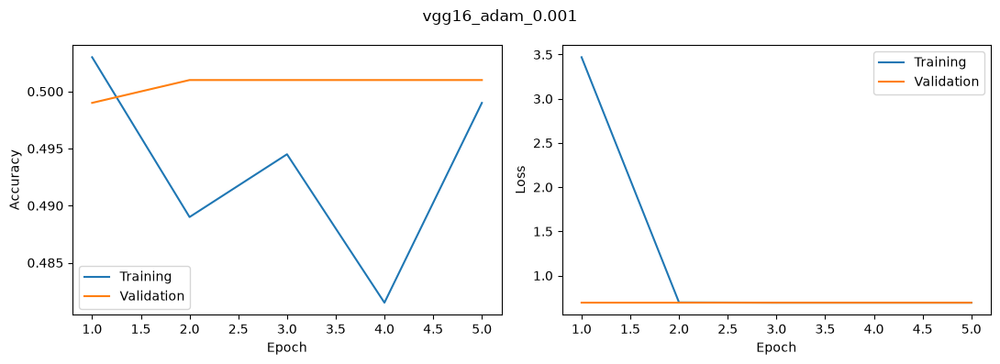

Found 2000 images belonging to 2 classes.


{'name': 'adam_0.0001', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 0.0001, 'epochs': 5, 'batch_size': 25} Trainable weights: 7145217
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 19s - 233ms/step - accuracy: 0.9270 - loss: 0.2803 - val_accuracy: 0.9610 - val_loss: 0.1215


Epoch 2/5


80/80 - 15s - 182ms/step - accuracy: 0.9620 - loss: 0.1217 - val_accuracy: 0.9670 - val_loss: 0.1089


... (2 outputs left out)

Epoch 4/5


80/80 - 15s - 182ms/step - accuracy: 0.9865 - loss: 0.0415 - val_accuracy: 0.9350 - val_loss: 0.3275


Epoch 5/5


80/80 - 15s - 182ms/step - accuracy: 0.9850 - loss: 0.0315 - val_accuracy: 0.9730 - val_loss: 0.1194


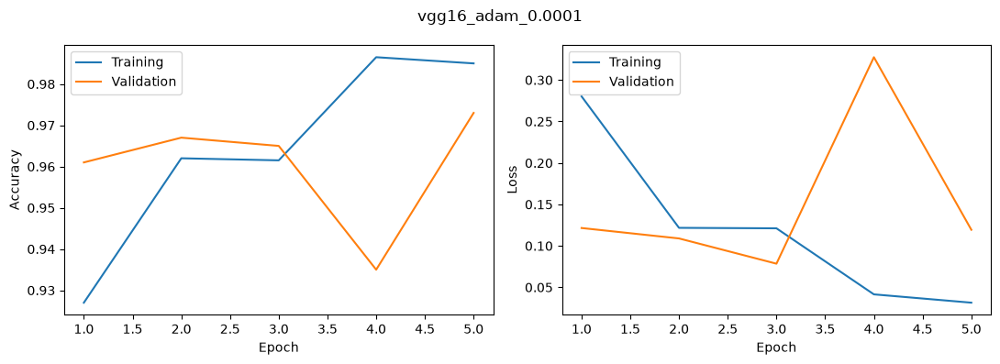

Found 2000 images belonging to 2 classes.


{'name': 'adam_1e-05', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 7145217
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 19s - 237ms/step - accuracy: 0.9565 - loss: 0.1196 - val_accuracy: 0.9720 - val_loss: 0.0642


Epoch 2/5


80/80 - 15s - 182ms/step - accuracy: 0.9655 - loss: 0.0752 - val_accuracy: 0.9680 - val_loss: 0.0722


... (2 outputs left out)

Epoch 4/5


80/80 - 15s - 182ms/step - accuracy: 0.9780 - loss: 0.0498 - val_accuracy: 0.9690 - val_loss: 0.0698


Epoch 5/5


80/80 - 15s - 182ms/step - accuracy: 0.9805 - loss: 0.0380 - val_accuracy: 0.9730 - val_loss: 0.0666


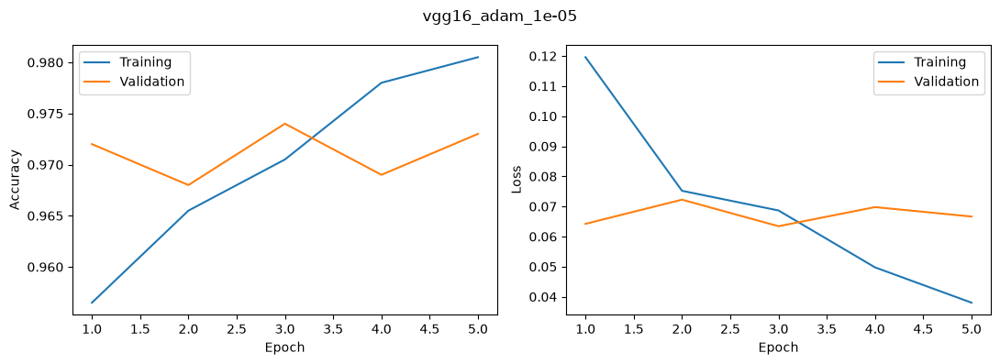

Found 2000 images belonging to 2 classes.


{'name': 'adam_1e-06', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 1e-06, 'epochs': 5, 'batch_size': 25} Trainable weights: 7145217
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 19s - 235ms/step - accuracy: 0.9570 - loss: 0.1117 - val_accuracy: 0.9700 - val_loss: 0.0685


Epoch 2/5


80/80 - 15s - 183ms/step - accuracy: 0.9530 - loss: 0.1048 - val_accuracy: 0.9700 - val_loss: 0.0667


... (2 outputs left out)

Epoch 4/5


80/80 - 15s - 184ms/step - accuracy: 0.9590 - loss: 0.0880 - val_accuracy: 0.9690 - val_loss: 0.0662


Epoch 5/5


80/80 - 15s - 184ms/step - accuracy: 0.9640 - loss: 0.0819 - val_accuracy: 0.9690 - val_loss: 0.0666


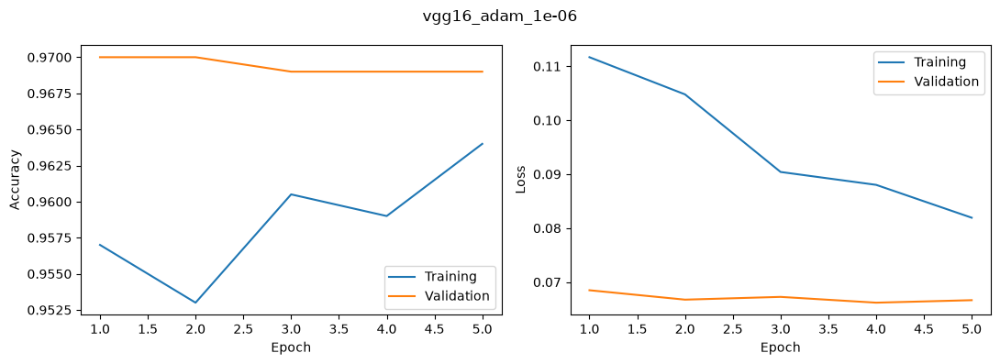

Found 2000 images belonging to 2 classes.


{'name': 'sgd', 'blocks': 1, 'optimizer': 'sgd', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 7145217
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 17s - 212ms/step - accuracy: 0.9580 - loss: 0.1125 - val_accuracy: 0.9670 - val_loss: 0.0695


Epoch 2/5


80/80 - 14s - 173ms/step - accuracy: 0.9515 - loss: 0.1149 - val_accuracy: 0.9680 - val_loss: 0.0692


... (2 outputs left out)

Epoch 4/5


80/80 - 14s - 173ms/step - accuracy: 0.9500 - loss: 0.1068 - val_accuracy: 0.9670 - val_loss: 0.0692


Epoch 5/5


80/80 - 14s - 173ms/step - accuracy: 0.9595 - loss: 0.0958 - val_accuracy: 0.9680 - val_loss: 0.0692


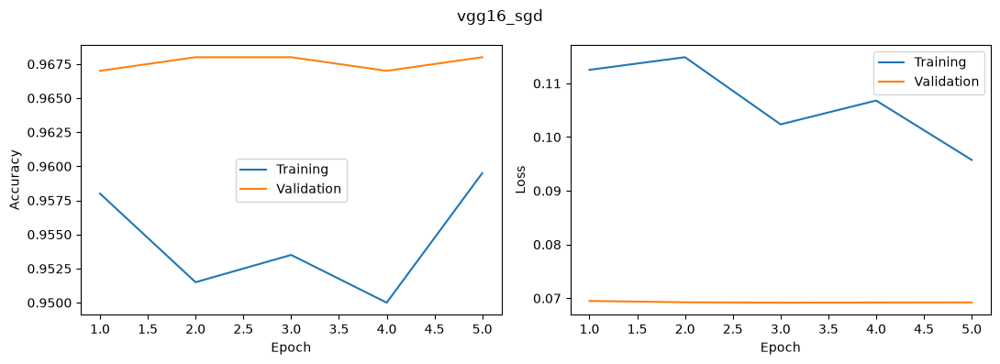

Found 2000 images belonging to 2 classes.


{'name': 'rmsprop', 'blocks': 1, 'optimizer': 'rmsprop', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 7145217
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 18s - 224ms/step - accuracy: 0.9585 - loss: 0.1099 - val_accuracy: 0.9710 - val_loss: 0.0685


Epoch 2/5


80/80 - 14s - 178ms/step - accuracy: 0.9695 - loss: 0.0738 - val_accuracy: 0.9680 - val_loss: 0.0683


... (2 outputs left out)

Epoch 4/5


80/80 - 14s - 178ms/step - accuracy: 0.9810 - loss: 0.0455 - val_accuracy: 0.9720 - val_loss: 0.0708


Epoch 5/5


80/80 - 14s - 178ms/step - accuracy: 0.9835 - loss: 0.0356 - val_accuracy: 0.9730 - val_loss: 0.0790


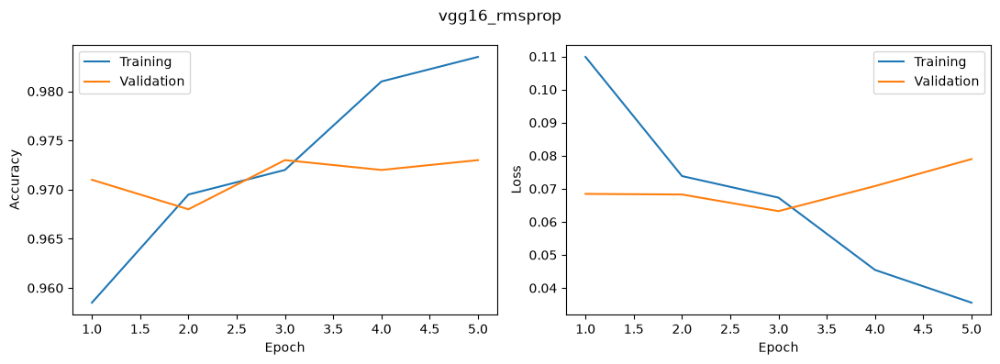

Found 2000 images belonging to 2 classes.


{'name': 'two_blocks', 'blocks': 2, 'optimizer': 'adam', 'learning_rate': 1e-05, 'epochs': 10, 'batch_size': 50} Trainable weights: 13044993
Epoch 1/10


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


40/40 - 36s - 890ms/step - accuracy: 0.9540 - loss: 0.1190 - val_accuracy: 0.9700 - val_loss: 0.0690


Epoch 2/10


40/40 - 17s - 432ms/step - accuracy: 0.9715 - loss: 0.0748 - val_accuracy: 0.9660 - val_loss: 0.0795


... (4 outputs left out)

Epoch 5/10


40/40 - 17s - 434ms/step - accuracy: 0.9830 - loss: 0.0565 - val_accuracy: 0.9770 - val_loss: 0.0603


Epoch 6/10


40/40 - 17s - 432ms/step - accuracy: 0.9895 - loss: 0.0277 - val_accuracy: 0.9780 - val_loss: 0.0651


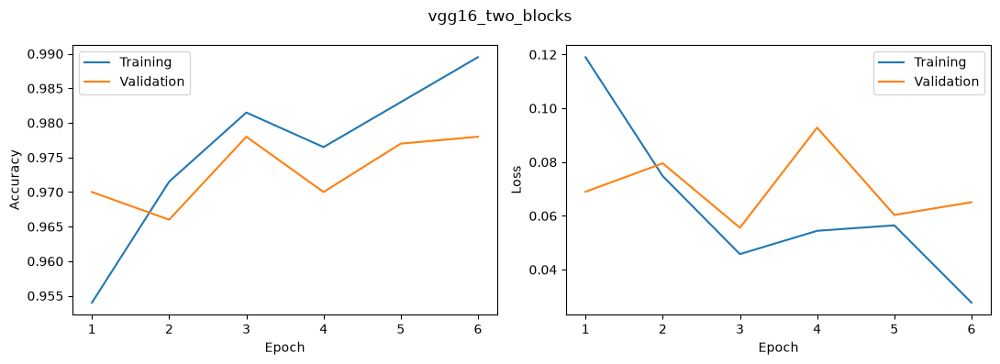

,name,blocks,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,val_loss,val_accuracy,seconds
0,adam_0.001,1,adam,0.001000,5,25,5,3,0.693119,0.501,82.385081
1,adam_0.0001,1,adam,0.000100,5,25,5,3,0.078490,0.965,81.320750
2,adam_1e-05,1,adam,0.000010,5,25,5,3,0.063430,0.974,81.697208
3,adam_1e-06,1,adam,0.000001,5,25,5,4,0.066177,0.969,81.820867
4,sgd,1,sgd,0.000010,5,25,5,3,0.069174,0.968,76.793145
5,rmsprop,1,rmsprop,0.000010,5,25,5,3,0.063243,0.973,79.326009
6,two_blocks,2,adam,0.000010,10,50,6,3,0.055567,0.978,126.762699


In [15]:
finetune_results, best_config_ft = fine_tune(start_file, fine_configs, validation_generator, preprocess_input, NAME)

## Results

In [16]:
# Test data are evaluated after choosing the fine-tuning checkpoint on validation loss.
model = keras.models.load_model(best_file)
base = model.get_layer(NAME)
head = next(layer for layer in model.layers if isinstance(layer, keras.Sequential))
fine_loss, fine_accuracy = model.evaluate(test_generator, verbose=0)
result = {'model': NAME, 'fine_experiment': best_config_ft['name'],
          'val_loss': float(finetune_results['val_loss'].min()),
          'val_accuracy': float(finetune_results.sort_values('val_loss').iloc[0]['val_accuracy']),
          'test_loss': fine_loss, 'test_accuracy': fine_accuracy,
          'head_experiment': str(best['name'])}
previous = json.loads(Path(f'../lab8/results/{NAME}_metrics.json').read_text())
comparison = pd.DataFrame([{'stage': 'transfer', **previous}, {'stage': 'fine_tuning', **result}])
comparison.to_csv(f'results/{NAME}_comparison.csv', index=False)
display(comparison)
Path(f'results/{NAME}_metrics.json').write_text(json.dumps(result, indent=2))

,stage,model,experiment,val_loss,val_accuracy,test_loss,test_accuracy,parameters,fine_experiment,head_experiment
0,transfer,vgg16,dropout_0.8,0.069597,0.967,0.124012,0.957,14780481.0,NaN,NaN
1,fine_tuning,vgg16,NaN,0.055567,0.978,0.126937,0.959,NaN,two_blocks,dropout_0.8


242

## Saving

In [17]:
save_bundle(model, base, head, f'models/{NAME}', config)

## New images

In [18]:
image_dir = Path('../lab7/images')
manifest = pd.DataFrame(json.loads((image_dir / 'manifest.json').read_text()))
images = []
for filename in manifest['file']:
    image = keras.utils.load_img(image_dir / filename, target_size=(SIZE, SIZE))
    images.append(keras.utils.img_to_array(image))
images = np.array(images)

In [ ]:
def predict_images(model, images, manifest, preprocess_input, name):
    probabilities = model.predict(preprocess_input(images.copy()), batch_size=16, verbose=0).ravel()
    new_results = manifest[['file', 'class']].copy()
    new_results['dog_probability'] = probabilities
    new_results['prediction'] = [classes[int(p >= 0.5)] for p in probabilities]
    new_results['correct'] = new_results['class'] == new_results['prediction']
    display(new_results)
    print('External accuracy:', f"{new_results['correct'].mean():.2%}")
    new_results.to_csv(f'results/{name}_external.csv', index=False)
    fig, axs = plt.subplots(4, 5, figsize=(14, 11))
    for ax, row in zip(axs.flat, new_results.itertuples()):
        ax.imshow(Image.open(image_dir / row.file))
        ax.set_title(f'{row[2]} --> {row.prediction}', fontsize=9,
                     color='green' if row.correct else 'red')
        ax.axis('off')
    plt.tight_layout()
    fig.savefig(f'results/{name}_external.png', dpi=150)
    plt.show()
    return new_results

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,9.561803e-11,cat,True
1,cat_02.jpg,cat,8.527472e-01,dog,False
2,cat_03.jpg,cat,4.777017e-01,cat,True
3,cat_04.jpg,cat,2.469138e-01,cat,True
4,cat_05.jpg,cat,9.903106e-01,dog,False
5,dog_01.jpg,dog,9.994606e-01,dog,True
6,dog_02.jpg,dog,9.996057e-01,dog,True
7,dog_03.jpg,dog,9.999992e-01,dog,True
8,dog_04.jpg,dog,9.998318e-01,dog,True
9,dog_05.jpg,dog,8.898246e-01,dog,True


External accuracy: 75.00%


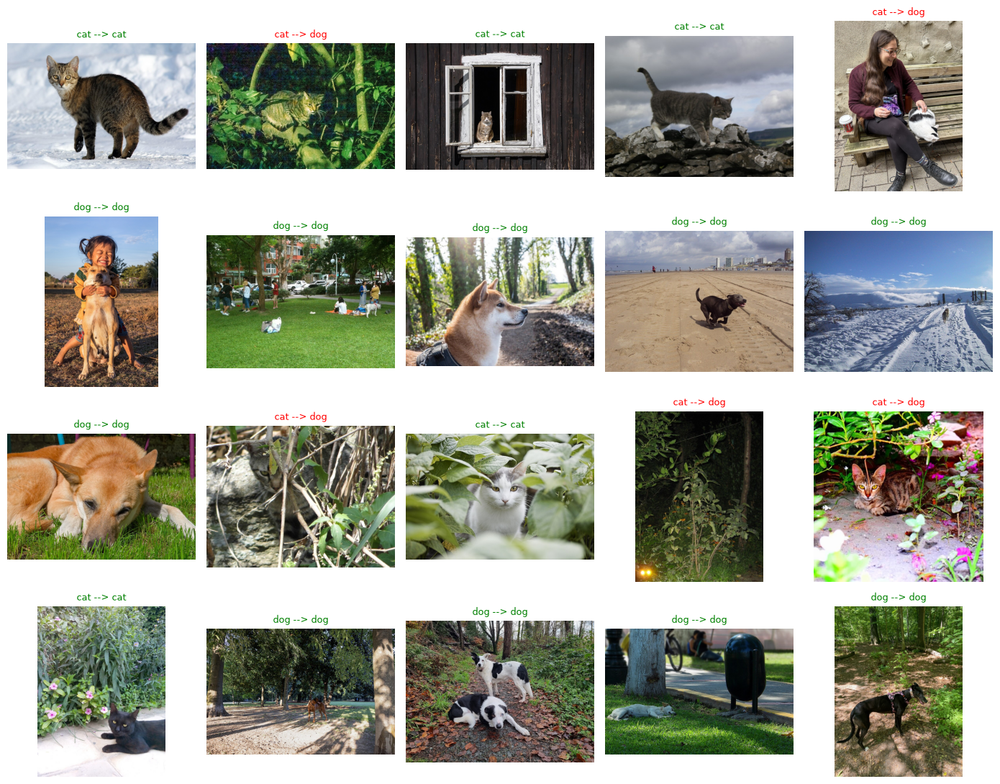

In [19]:
new_results = predict_images(model, images, manifest, preprocess_input, NAME)

In [21]:
previous_external = pd.read_csv(f'../lab8/results/{NAME}_external.csv')
external_comparison = previous_external[['file', 'class', 'prediction', 'correct']].merge(
    new_results[['file', 'prediction', 'correct']], on='file', suffixes=('_transfer', '_fine'))
display(external_comparison)
external_comparison.to_csv(f'results/{NAME}_external_comparison.csv', index=False)
print('Transfer:', previous_external['correct'].mean(), 'Fine tuning:', new_results['correct'].mean())

,file,class,prediction_transfer,correct_transfer,prediction_fine,correct_fine
0,cat_01.jpg,cat,cat,True,cat,True
1,cat_02.jpg,cat,dog,False,dog,False
2,cat_03.jpg,cat,dog,False,cat,True
3,cat_04.jpg,cat,cat,True,cat,True
4,cat_05.jpg,cat,dog,False,dog,False
5,dog_01.jpg,dog,dog,True,dog,True
6,dog_02.jpg,dog,dog,True,dog,True
7,dog_03.jpg,dog,dog,True,dog,True
8,dog_04.jpg,dog,dog,True,dog,True
9,dog_05.jpg,dog,dog,True,dog,True


Transfer: 0.7 Fine tuning: 0.75


In [ ]:
del model, base, head
keras.backend.clear_session()

# ResNet50

## Data

In [ ]:
NAME = 'resnet50'
preprocess_input = keras.applications.resnet50.preprocess_input

In [4]:
train_generator, validation_generator, test_generator = make_generators(preprocess_input)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


## Model

In [5]:
# Start the head search from the same frozen ImageNet features as lab 8.
base = keras.applications.ResNet50(
    weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3), pooling='avg')
base.trainable = False

In [6]:
# Reuse the frozen features computed in lab 8.
cache = DATA_ROOT / 'features' / f'{NAME}_{SIZE}'
features = {subset: np.load(cache / f'{subset}.npy') for subset in ['train', 'validation']}
labels = {'train': train_generator.classes.astype('float32'),
          'validation': validation_generator.classes.astype('float32')}
for subset in features:
    print(subset, features[subset].shape)

train (2000, 2048)
validation (1000, 2048)


## Head training

In [ ]:
head_dir = DATA_ROOT / 'models' / 'lab9' / 'heads'
results = []

### Reference

reference Validation: 97.60%, loss: 0.0583


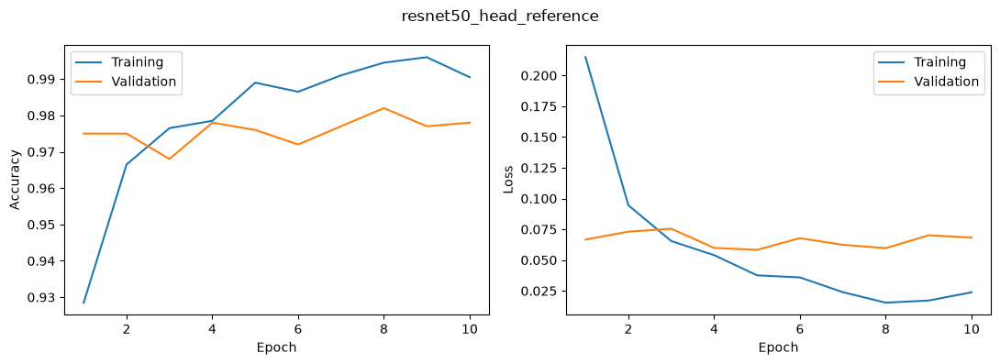

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,reference,128,0.5,0,adam,0.001,15,25,10,5,5.357883,0.058305,0.976,0.9905


In [10]:
results.append(train_heads(features, labels, head_configs['Reference'], NAME))

### Dense width

units_32 Validation: 98.00%, loss: 0.0550


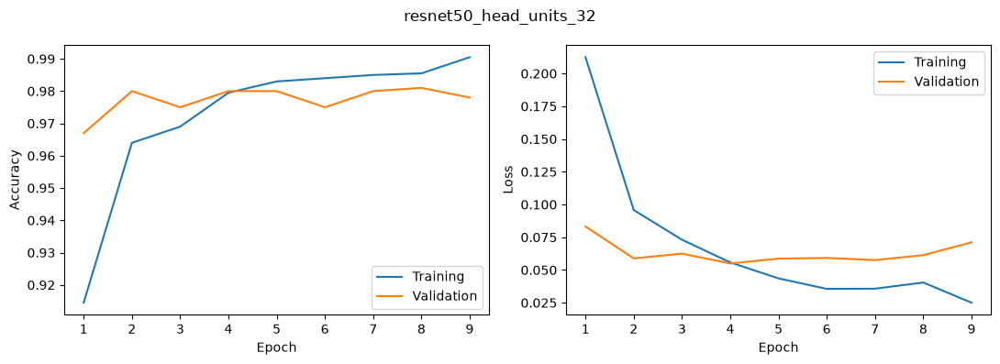

units_256 Validation: 98.00%, loss: 0.0584


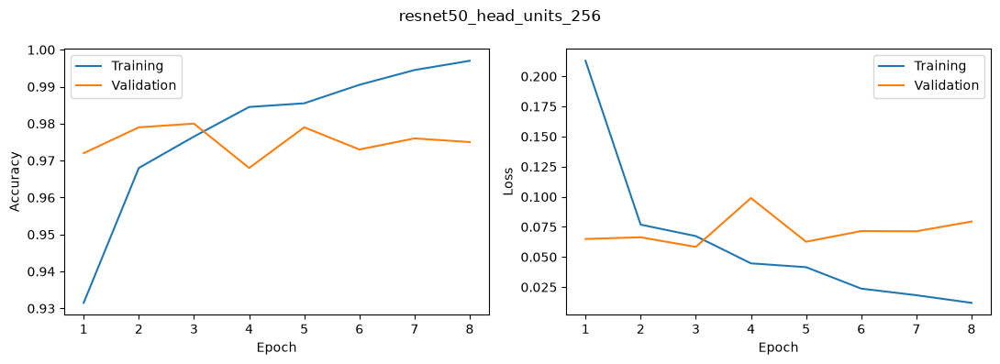

units_512 Validation: 97.50%, loss: 0.0653


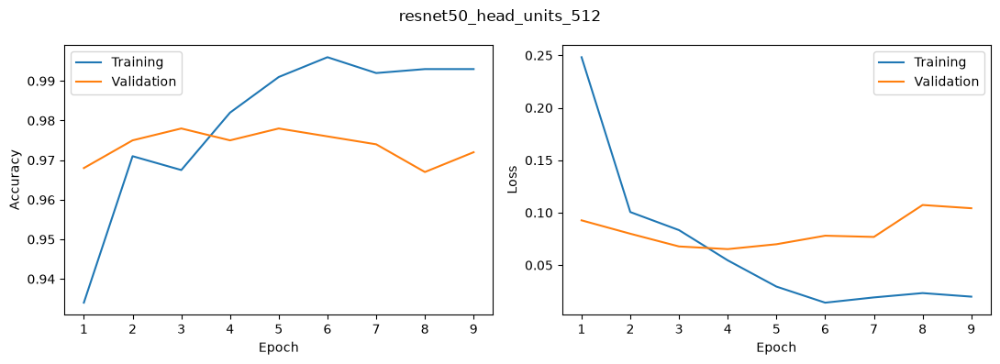

units_1024 Validation: 98.00%, loss: 0.0814


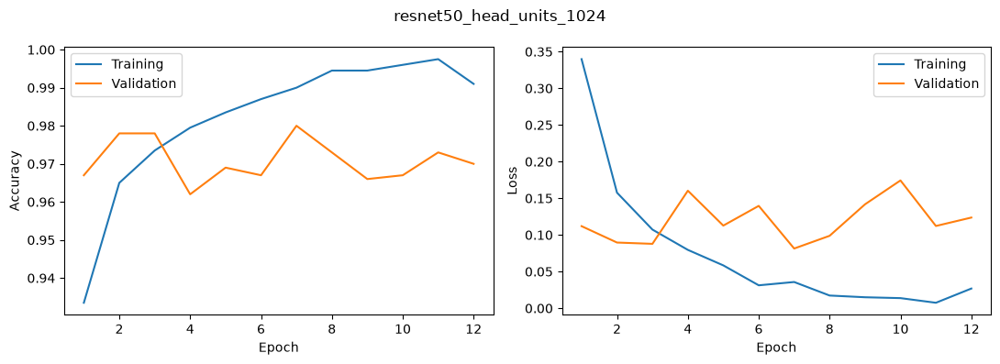

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
1,units_32,32,0.5,0,adam,0.001,15,25,9,4,4.808747,0.054979,0.980,0.9905
2,units_256,256,0.5,0,adam,0.001,15,25,8,3,4.774328,0.058365,0.980,0.9970
3,units_512,512,0.5,0,adam,0.001,15,25,9,4,5.222679,0.065260,0.975,0.9930
4,units_1024,1024,0.5,0,adam,0.001,15,25,12,7,6.369324,0.081420,0.980,0.9910


In [10]:
results.append(train_heads(features, labels, head_configs['Dense width'], NAME))

### Dropout

dropout_0.25 Validation: 97.50%, loss: 0.0693


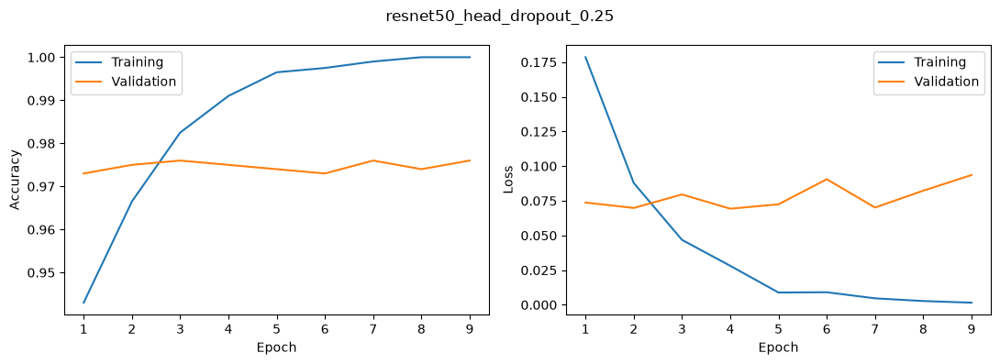

dropout_0.6 Validation: 98.00%, loss: 0.0558


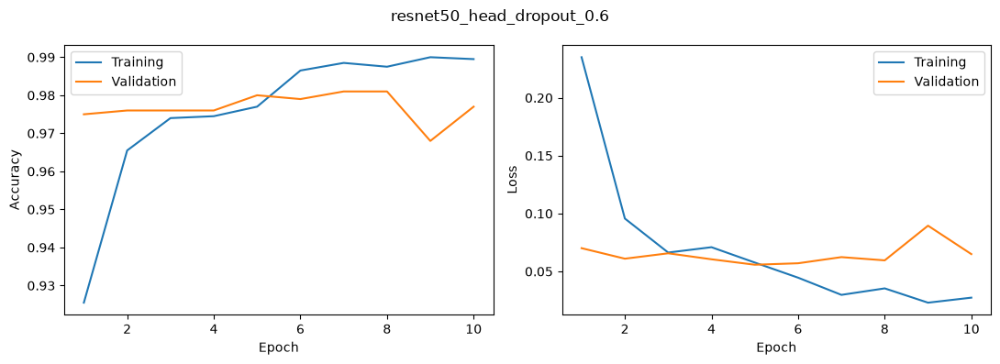

dropout_0.8 Validation: 97.90%, loss: 0.0513


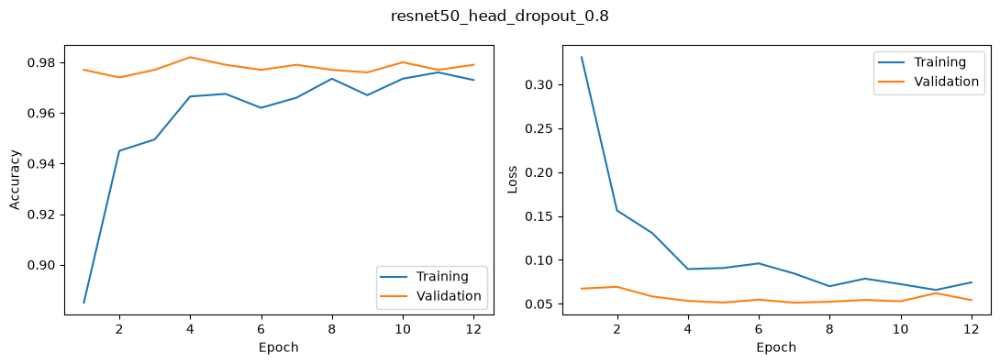

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
5,dropout_0.25,128,0.25,0,adam,0.001,15,25,9,4,5.079064,0.069293,0.975,1.0000
6,dropout_0.6,128,0.60,0,adam,0.001,15,25,10,5,4.725068,0.055775,0.980,0.9895
7,dropout_0.8,128,0.80,0,adam,0.001,15,25,12,7,5.687570,0.051291,0.979,0.9730


In [10]:
results.append(train_heads(features, labels, head_configs['Dropout'], NAME))

### Extra Dense layer

extra_32 Validation: 97.90%, loss: 0.0640


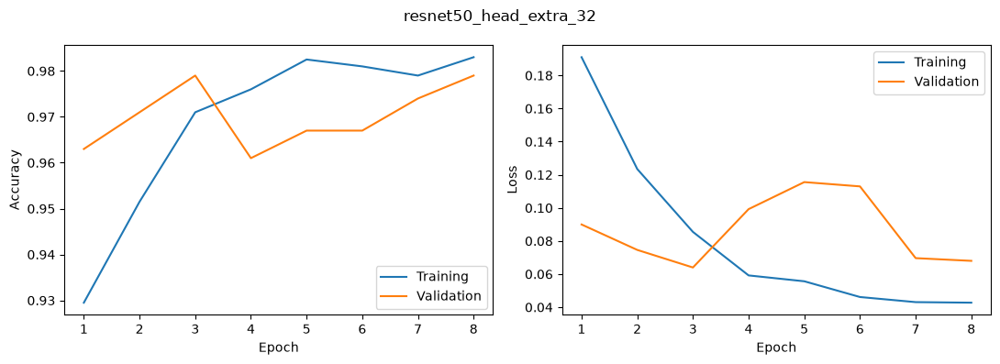

extra_128 Validation: 97.90%, loss: 0.0588


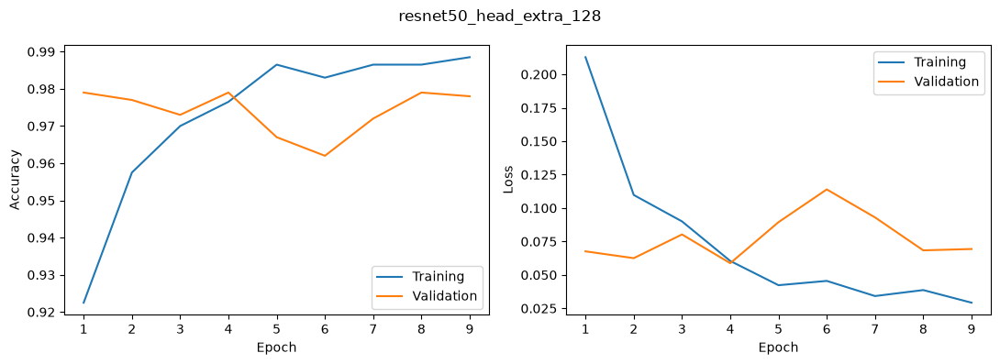

extra_256 Validation: 97.90%, loss: 0.0592


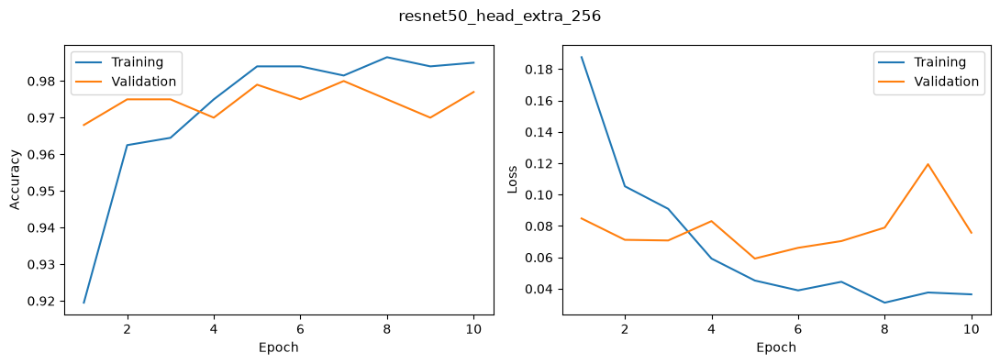

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
8,extra_32,128,0.5,32,adam,0.001,15,25,8,3,5.575336,0.063979,0.979,0.9830
9,extra_128,128,0.5,128,adam,0.001,15,25,9,4,6.154449,0.058775,0.979,0.9885
10,extra_256,128,0.5,256,adam,0.001,15,25,10,5,5.353694,0.059248,0.979,0.9850


In [10]:
results.append(train_heads(features, labels, head_configs['Extra Dense layer'], NAME))

### Epochs

epochs_5 Validation: 97.60%, loss: 0.0583


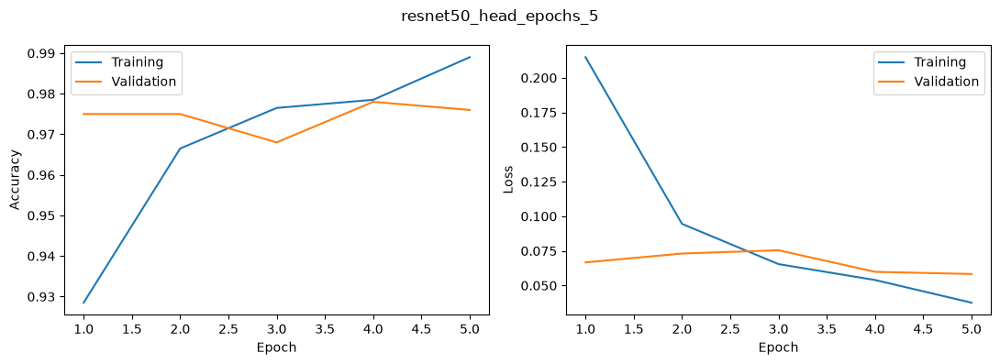

epochs_10 Validation: 97.60%, loss: 0.0583


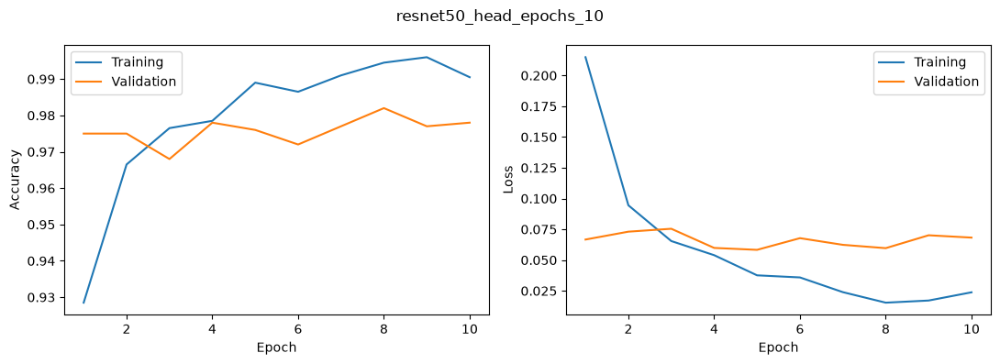

epochs_20 Validation: 97.60%, loss: 0.0583


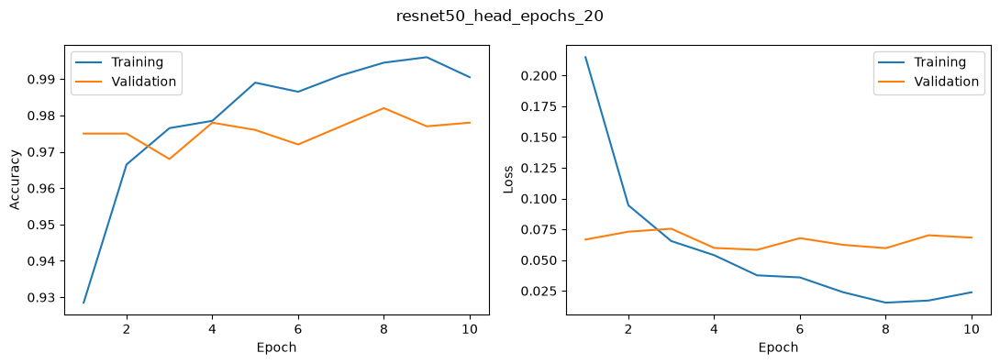

epochs_25 Validation: 97.60%, loss: 0.0583


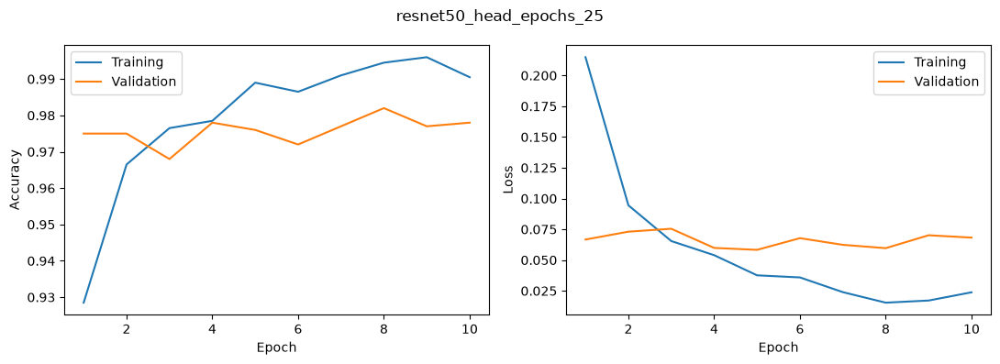

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
11,epochs_5,128,0.5,0,adam,0.001,5,25,5,5,3.303296,0.058305,0.976,0.9890
12,epochs_10,128,0.5,0,adam,0.001,10,25,10,5,4.734942,0.058305,0.976,0.9905
13,epochs_20,128,0.5,0,adam,0.001,20,25,10,5,4.743741,0.058305,0.976,0.9905
14,epochs_25,128,0.5,0,adam,0.001,25,25,10,5,6.276780,0.058305,0.976,0.9905


In [10]:
results.append(train_heads(features, labels, head_configs['Epochs'], NAME))

### Batch size

batch_50 Validation: 98.20%, loss: 0.0564


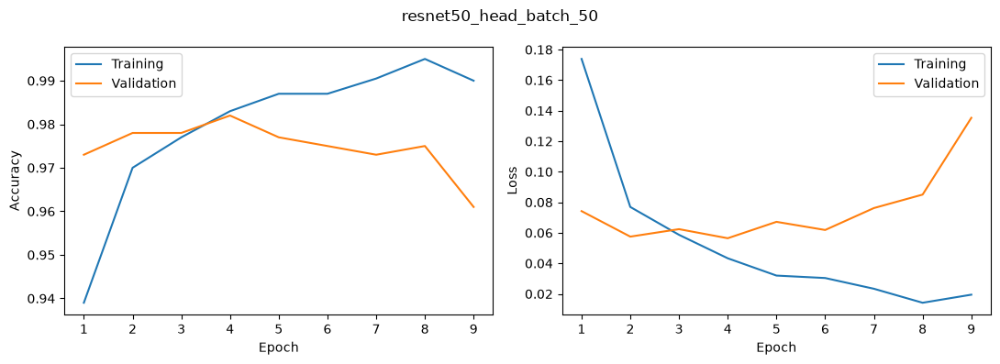

batch_100 Validation: 97.70%, loss: 0.0598


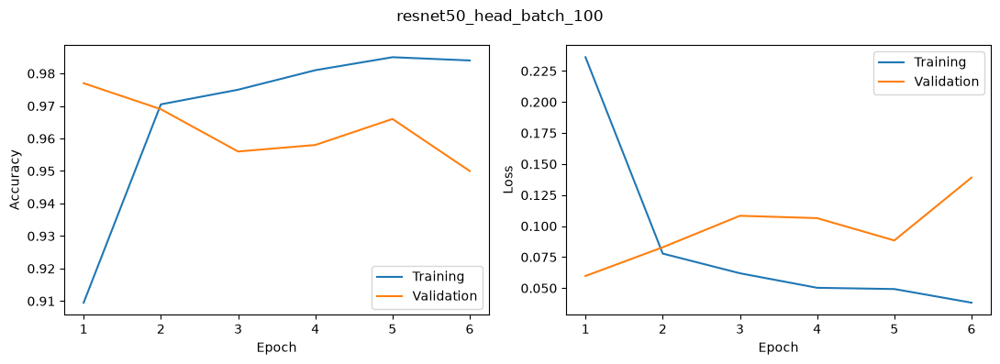

batch_125 Validation: 97.90%, loss: 0.0550


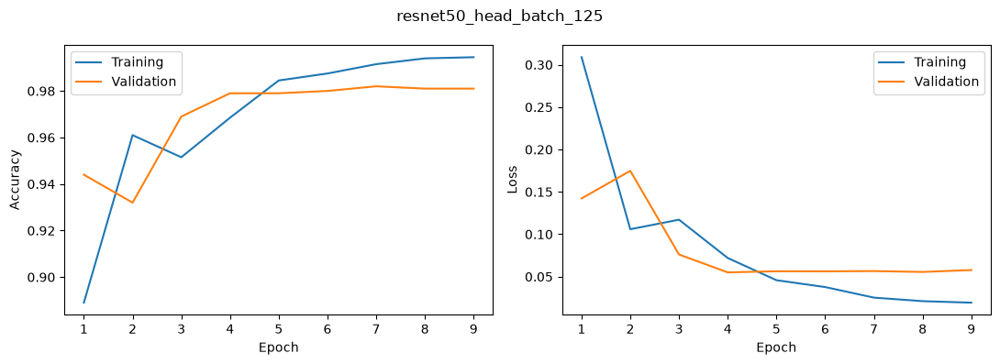

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
15,batch_50,128,0.5,0,adam,0.001,15,50,9,4,4.561643,0.056438,0.982,0.9900
16,batch_100,128,0.5,0,adam,0.001,15,100,6,1,3.473951,0.059794,0.977,0.9840
17,batch_125,128,0.5,0,adam,0.001,15,125,9,4,3.752712,0.055014,0.979,0.9945


In [10]:
results.append(train_heads(features, labels, head_configs['Batch size'], NAME))

### Optimizer

sgd Validation: 97.30%, loss: 0.0720


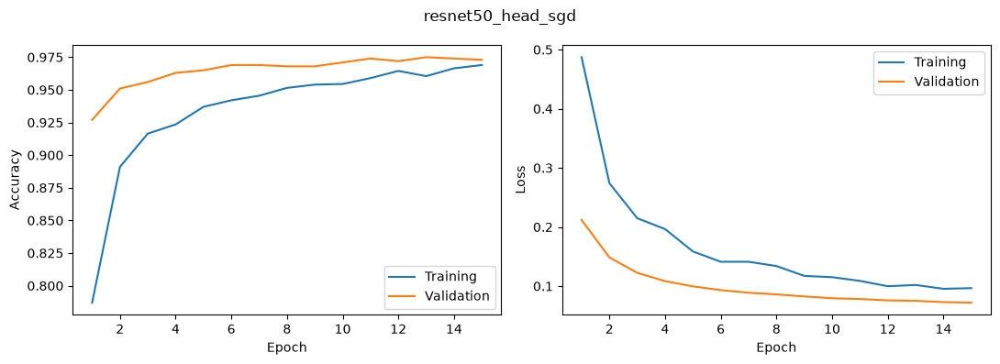

rmsprop Validation: 98.10%, loss: 0.0629


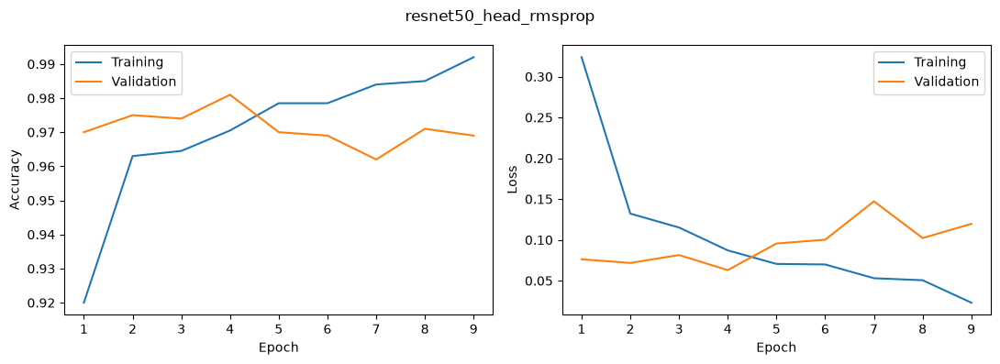

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
18,sgd,128,0.5,0,sgd,0.001,15,25,15,15,7.275625,0.071958,0.973,0.969
19,rmsprop,128,0.5,0,rmsprop,0.001,15,25,9,4,5.043412,0.062923,0.981,0.992


In [10]:
results.append(train_heads(features, labels, head_configs['Optimizer'], NAME))

### Learning rate

lr_0.0001 Validation: 97.60%, loss: 0.0609


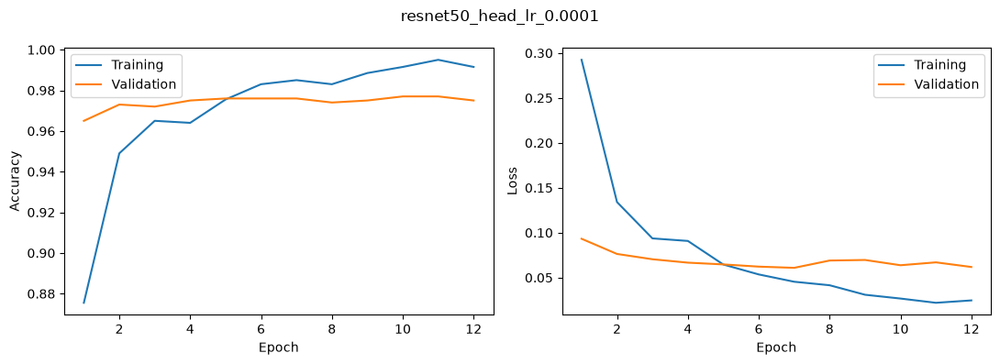

lr_1e-05 Validation: 97.10%, loss: 0.0823


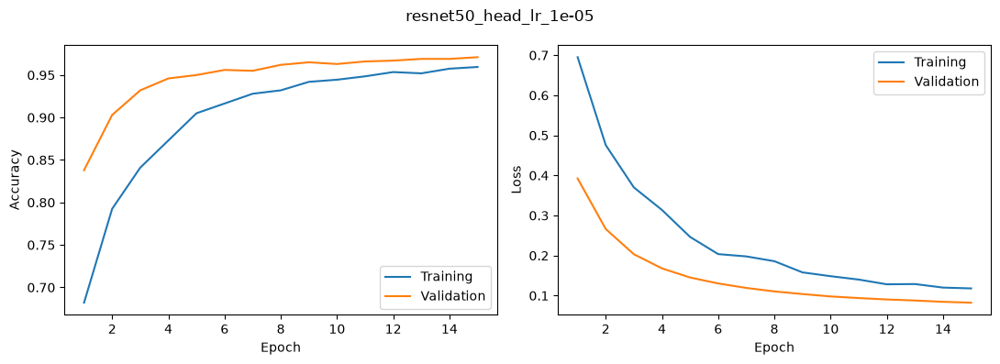

lr_1e-06 Validation: 87.40%, loss: 0.3250


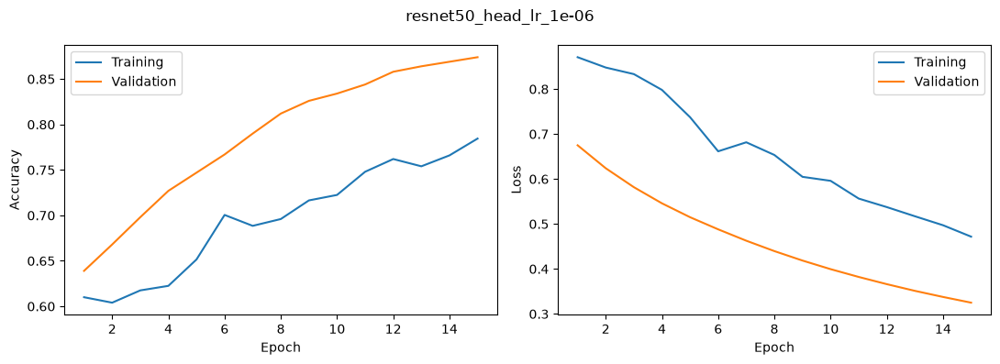

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
20,lr_0.0001,128,0.5,0,adam,0.000100,15,25,12,7,5.342886,0.060886,0.976,0.9915
21,lr_1e-05,128,0.5,0,adam,0.000010,15,25,15,15,6.405419,0.082322,0.971,0.9595
22,lr_1e-06,128,0.5,0,adam,0.000001,15,25,15,15,6.572902,0.324985,0.874,0.7845


In [10]:
results.append(train_heads(features, labels, head_configs['Learning rate'], NAME))

In [10]:
results = pd.concat(results, ignore_index=True)
results.to_csv(f'results/{NAME}_experiments.csv', index=False)
display(results)

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,reference,128,0.50,0,adam,0.001000,15,25,10,5,5.357883,0.058305,0.976,0.9905
1,units_32,32,0.50,0,adam,0.001000,15,25,9,4,4.808747,0.054979,0.980,0.9905
2,units_256,256,0.50,0,adam,0.001000,15,25,8,3,4.774328,0.058365,0.980,0.9970
3,units_512,512,0.50,0,adam,0.001000,15,25,9,4,5.222679,0.065260,0.975,0.9930
4,units_1024,1024,0.50,0,adam,0.001000,15,25,12,7,6.369324,0.081420,0.980,0.9910
5,dropout_0.25,128,0.25,0,adam,0.001000,15,25,9,4,5.079064,0.069293,0.975,1.0000
6,dropout_0.6,128,0.60,0,adam,0.001000,15,25,10,5,4.725068,0.055775,0.980,0.9895
7,dropout_0.8,128,0.80,0,adam,0.001000,15,25,12,7,5.687570,0.051291,0.979,0.9730
8,extra_32,128,0.50,32,adam,0.001000,15,25,8,3,5.575336,0.063979,0.979,0.9830
9,extra_128,128,0.50,128,adam,0.001000,15,25,9,4,6.154449,0.058775,0.979,0.9885


In [11]:
model, head, best, config = assemble_model(base, results, NAME)

In [12]:
model_dir = DATA_ROOT / 'models' / 'lab9'
start_file = model_dir / f'{NAME}_start.keras'
best_file = model_dir / f'{NAME}.keras'
model.save(start_file)
# Compare the tuned head with the lab 8 checkpoint before fine-tuning.
transfer = load_bundle(f'../lab8/models/{NAME}')
transfer.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
transfer_loss, transfer_accuracy = transfer.evaluate(validation_generator, verbose=0)
head_loss, head_accuracy = model.evaluate(validation_generator, verbose=0)
print('Lab 8 validation:', transfer_loss, transfer_accuracy)
print('Tuned head validation:', head_loss, head_accuracy)
del transfer

Lab 8 validation: 0.05129063129425049 0.9789999723434448
Tuned head validation: 0.05129063129425049 0.9789999723434448


## Fine tuning

Found 2000 images belonging to 2 classes.


{'name': 'adam_0.001', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 5, 'batch_size': 25} Trainable weights: 4721921
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 22s - 281ms/step - accuracy: 0.8965 - loss: 0.6087 - val_accuracy: 0.9450 - val_loss: 0.1540


Epoch 2/5


80/80 - 7s - 88ms/step - accuracy: 0.9505 - loss: 0.1311 - val_accuracy: 0.9710 - val_loss: 0.0549


... (2 outputs left out)

Epoch 4/5


80/80 - 7s - 86ms/step - accuracy: 0.9595 - loss: 0.1124 - val_accuracy: 0.9700 - val_loss: 0.0673


Epoch 5/5


80/80 - 7s - 85ms/step - accuracy: 0.9765 - loss: 0.0601 - val_accuracy: 0.9740 - val_loss: 0.0556


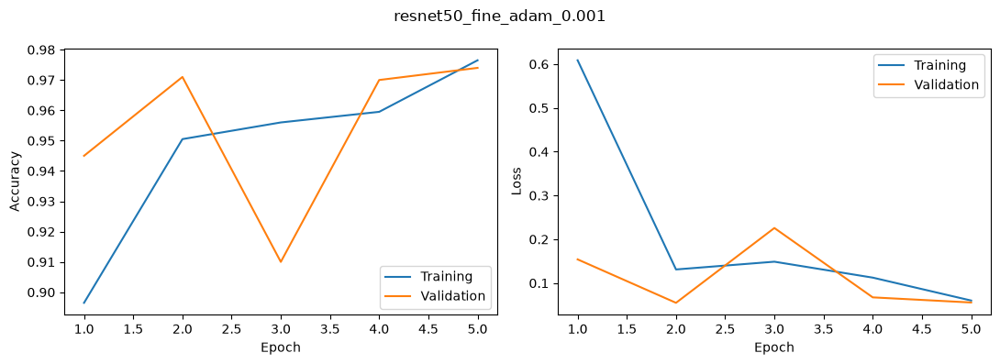

Found 2000 images belonging to 2 classes.


{'name': 'adam_0.0001', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 0.0001, 'epochs': 5, 'batch_size': 25} Trainable weights: 4721921
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 25s - 312ms/step - accuracy: 0.9720 - loss: 0.0775 - val_accuracy: 0.9700 - val_loss: 0.0708


Epoch 2/5


80/80 - 7s - 86ms/step - accuracy: 0.9870 - loss: 0.0392 - val_accuracy: 0.9750 - val_loss: 0.0767


... (2 outputs left out)

Epoch 4/5


80/80 - 7s - 86ms/step - accuracy: 0.9940 - loss: 0.0168 - val_accuracy: 0.9720 - val_loss: 0.1036


Epoch 5/5


80/80 - 7s - 85ms/step - accuracy: 0.9950 - loss: 0.0116 - val_accuracy: 0.9720 - val_loss: 0.1135


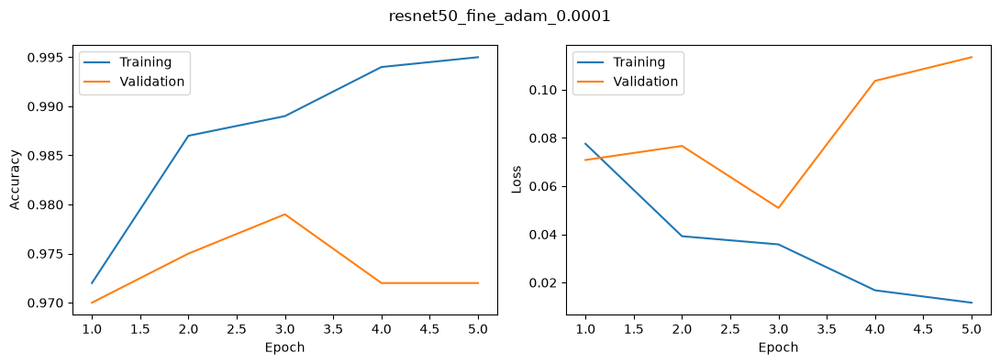

Found 2000 images belonging to 2 classes.


{'name': 'adam_1e-05', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 4721921
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 22s - 277ms/step - accuracy: 0.9775 - loss: 0.0617 - val_accuracy: 0.9800 - val_loss: 0.0503


Epoch 2/5


80/80 - 7s - 86ms/step - accuracy: 0.9835 - loss: 0.0413 - val_accuracy: 0.9770 - val_loss: 0.0526


Epoch 3/5


80/80 - 7s - 86ms/step - accuracy: 0.9845 - loss: 0.0455 - val_accuracy: 0.9780 - val_loss: 0.0538


Epoch 4/5


80/80 - 7s - 86ms/step - accuracy: 0.9865 - loss: 0.0346 - val_accuracy: 0.9780 - val_loss: 0.0551


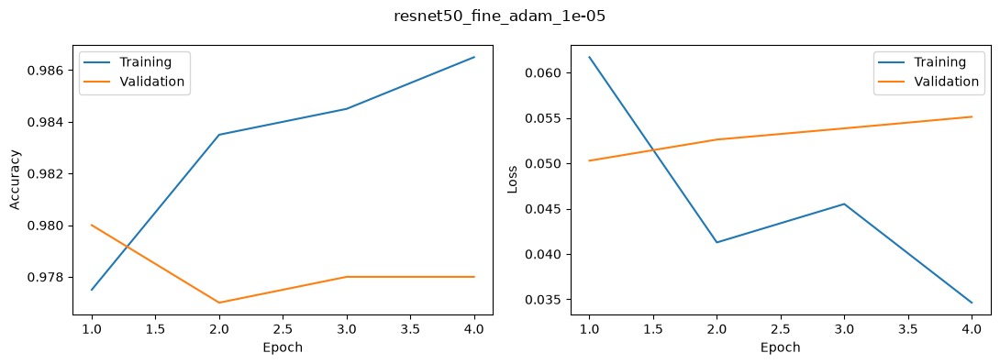

Found 2000 images belonging to 2 classes.


{'name': 'adam_1e-06', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 1e-06, 'epochs': 5, 'batch_size': 25} Trainable weights: 4721921
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 21s - 267ms/step - accuracy: 0.9760 - loss: 0.0634 - val_accuracy: 0.9810 - val_loss: 0.0505


Epoch 2/5


80/80 - 7s - 90ms/step - accuracy: 0.9780 - loss: 0.0535 - val_accuracy: 0.9800 - val_loss: 0.0505


... (2 outputs left out)

Epoch 4/5


80/80 - 7s - 89ms/step - accuracy: 0.9750 - loss: 0.0655 - val_accuracy: 0.9800 - val_loss: 0.0501


Epoch 5/5


80/80 - 7s - 87ms/step - accuracy: 0.9775 - loss: 0.0581 - val_accuracy: 0.9800 - val_loss: 0.0503


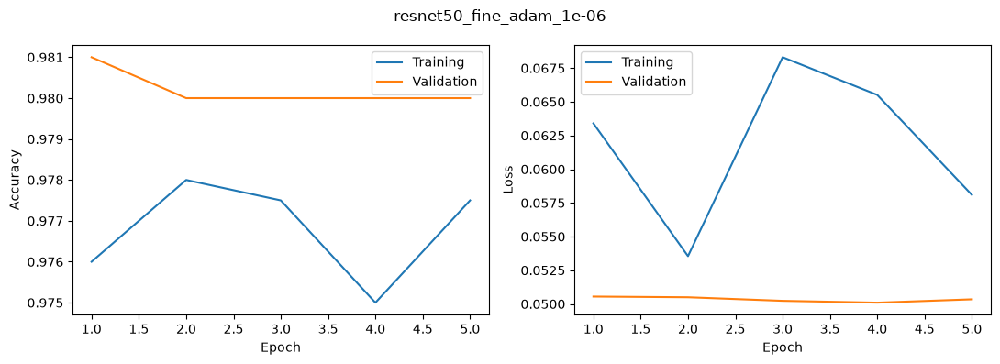

Found 2000 images belonging to 2 classes.


{'name': 'sgd', 'blocks': 1, 'optimizer': 'sgd', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 4721921
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 21s - 257ms/step - accuracy: 0.9755 - loss: 0.0643 - val_accuracy: 0.9800 - val_loss: 0.0513


Epoch 2/5


80/80 - 7s - 85ms/step - accuracy: 0.9760 - loss: 0.0563 - val_accuracy: 0.9800 - val_loss: 0.0512


... (2 outputs left out)

Epoch 4/5


80/80 - 7s - 86ms/step - accuracy: 0.9705 - loss: 0.0741 - val_accuracy: 0.9800 - val_loss: 0.0511


Epoch 5/5


80/80 - 7s - 86ms/step - accuracy: 0.9725 - loss: 0.0675 - val_accuracy: 0.9800 - val_loss: 0.0511


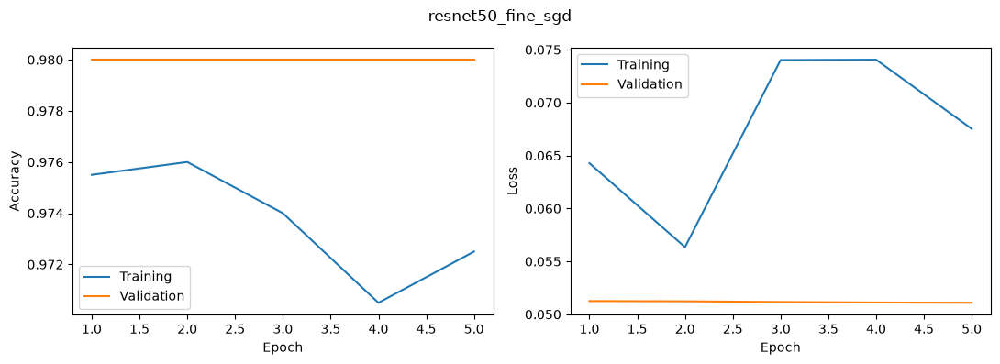

Found 2000 images belonging to 2 classes.


{'name': 'rmsprop', 'blocks': 1, 'optimizer': 'rmsprop', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 4721921
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 22s - 276ms/step - accuracy: 0.9765 - loss: 0.0599 - val_accuracy: 0.9810 - val_loss: 0.0522


Epoch 2/5


80/80 - 7s - 85ms/step - accuracy: 0.9850 - loss: 0.0415 - val_accuracy: 0.9770 - val_loss: 0.0533


Epoch 3/5


80/80 - 7s - 85ms/step - accuracy: 0.9845 - loss: 0.0509 - val_accuracy: 0.9810 - val_loss: 0.0544


Epoch 4/5


80/80 - 7s - 84ms/step - accuracy: 0.9850 - loss: 0.0408 - val_accuracy: 0.9790 - val_loss: 0.0605


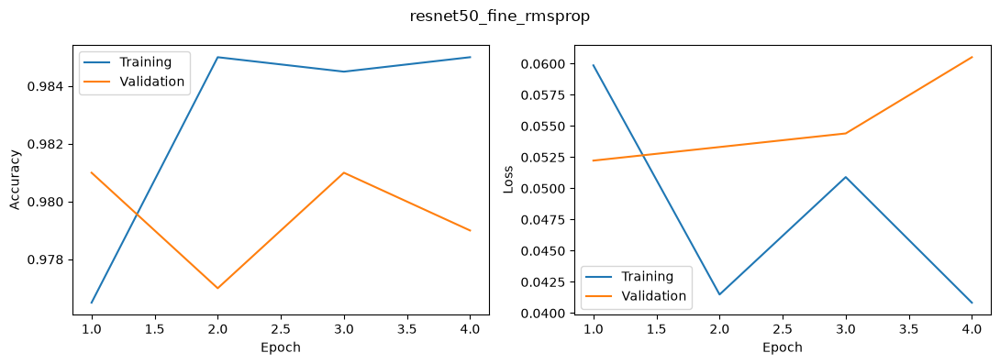

Found 2000 images belonging to 2 classes.


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


{'name': 'two_blocks', 'blocks': 2, 'optimizer': 'adam', 'learning_rate': 1e-05, 'epochs': 10, 'batch_size': 50} Trainable weights: 9181441
Epoch 1/10


40/40 - 28s - 688ms/step - accuracy: 0.9770 - loss: 0.0662 - val_accuracy: 0.9800 - val_loss: 0.0514


Epoch 2/10


40/40 - 7s - 173ms/step - accuracy: 0.9885 - loss: 0.0352 - val_accuracy: 0.9790 - val_loss: 0.0556


Epoch 3/10


40/40 - 7s - 175ms/step - accuracy: 0.9920 - loss: 0.0272 - val_accuracy: 0.9800 - val_loss: 0.0539


Epoch 4/10


40/40 - 7s - 175ms/step - accuracy: 0.9940 - loss: 0.0187 - val_accuracy: 0.9760 - val_loss: 0.0636


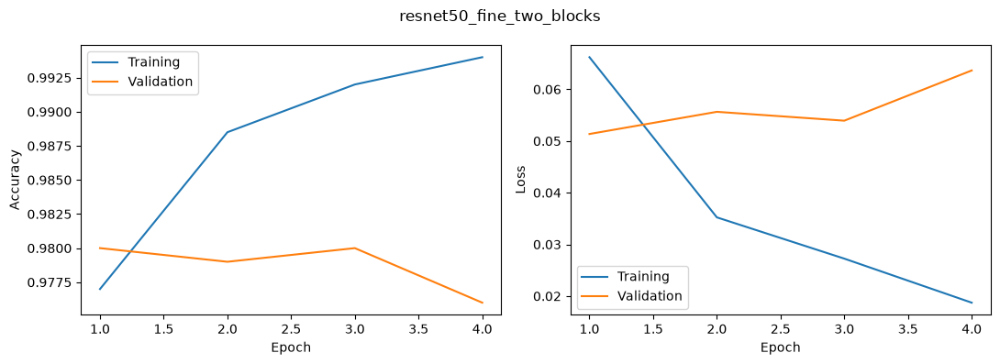

,name,blocks,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,val_loss,val_accuracy,seconds
0,adam_0.001,1,adam,0.001000,5,25,5,2,0.054871,0.971,52.558486
1,adam_0.0001,1,adam,0.000100,5,25,5,3,0.050923,0.979,55.097850
2,adam_1e-05,1,adam,0.000010,5,25,4,1,0.050284,0.980,45.204320
3,adam_1e-06,1,adam,0.000001,5,25,5,4,0.050095,0.980,52.242072
4,sgd,1,sgd,0.000010,5,25,5,5,0.051092,0.980,50.480817
5,rmsprop,1,rmsprop,0.000010,5,25,4,1,0.052229,0.981,44.901258
6,two_blocks,2,adam,0.000010,10,50,4,1,0.051354,0.980,51.130445


In [15]:
finetune_results, best_config_ft = fine_tune(start_file, fine_configs, validation_generator, preprocess_input, NAME)

## Results

In [16]:
# Test data are evaluated after choosing the fine-tuning checkpoint on validation loss.
model = keras.models.load_model(best_file)
base = model.get_layer(NAME)
head = next(layer for layer in model.layers if isinstance(layer, keras.Sequential))
fine_loss, fine_accuracy = model.evaluate(test_generator, verbose=0)
result = {'model': NAME, 'fine_experiment': best_config_ft['name'],
          'val_loss': float(finetune_results['val_loss'].min()),
          'val_accuracy': float(finetune_results.sort_values('val_loss').iloc[0]['val_accuracy']),
          'test_loss': fine_loss, 'test_accuracy': fine_accuracy,
          'head_experiment': str(best['name'])}
previous = json.loads(Path(f'../lab8/results/{NAME}_metrics.json').read_text())
comparison = pd.DataFrame([{'stage': 'transfer', **previous}, {'stage': 'fine_tuning', **result}])
comparison.to_csv(f'results/{NAME}_comparison.csv', index=False)
display(comparison)
Path(f'results/{NAME}_metrics.json').write_text(json.dumps(result, indent=2))

,stage,model,experiment,val_loss,val_accuracy,test_loss,test_accuracy,parameters,fine_experiment,head_experiment
0,transfer,resnet50,dropout_0.8,0.051291,0.979,0.076201,0.966,23850113.0,NaN,NaN
1,fine_tuning,resnet50,NaN,0.050095,0.980,0.073502,0.968,NaN,adam_1e-06,dropout_0.8


245

## Saving

In [17]:
save_bundle(model, base, head, f'models/{NAME}', config)

## New images

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,0.125050,cat,True
1,cat_02.jpg,cat,0.758709,dog,False
2,cat_03.jpg,cat,0.555863,dog,False
3,cat_04.jpg,cat,0.179929,cat,True
4,cat_05.jpg,cat,0.338204,cat,True
5,dog_01.jpg,dog,1.000000,dog,True
6,dog_02.jpg,dog,0.997276,dog,True
7,dog_03.jpg,dog,0.999499,dog,True
8,dog_04.jpg,dog,0.971510,dog,True
9,dog_05.jpg,dog,0.408226,cat,False


External accuracy: 75.00%


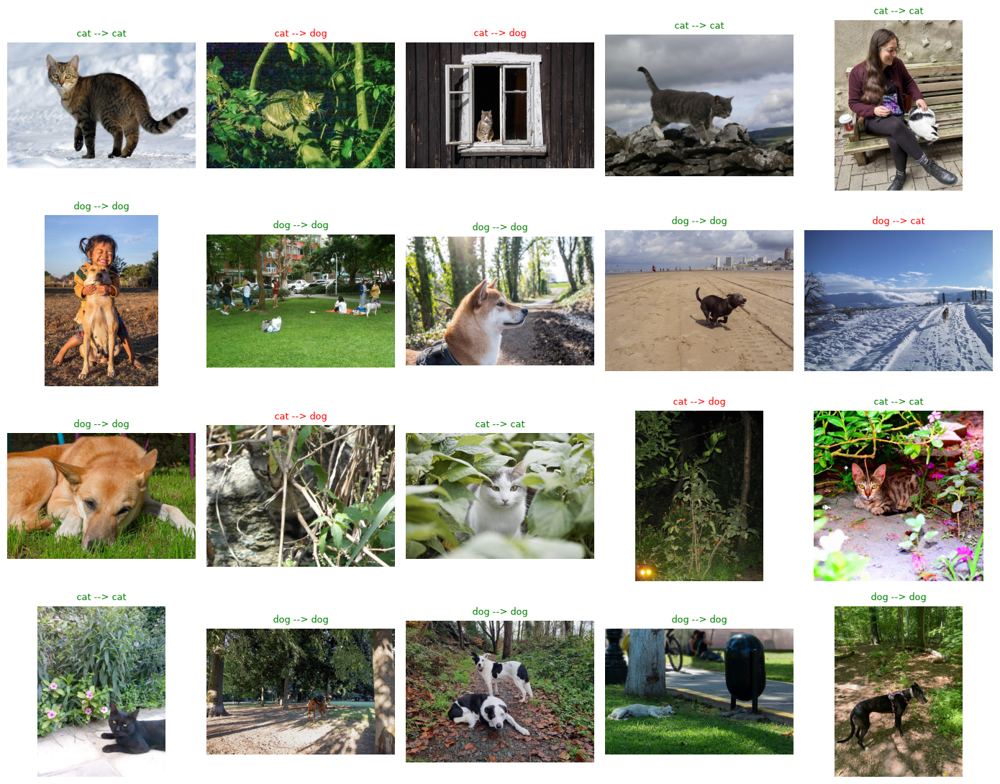

In [19]:
new_results = predict_images(model, images, manifest, preprocess_input, NAME)

In [21]:
previous_external = pd.read_csv(f'../lab8/results/{NAME}_external.csv')
external_comparison = previous_external[['file', 'class', 'prediction', 'correct']].merge(
    new_results[['file', 'prediction', 'correct']], on='file', suffixes=('_transfer', '_fine'))
display(external_comparison)
external_comparison.to_csv(f'results/{NAME}_external_comparison.csv', index=False)
print('Transfer:', previous_external['correct'].mean(), 'Fine tuning:', new_results['correct'].mean())

,file,class,prediction_transfer,correct_transfer,prediction_fine,correct_fine
0,cat_01.jpg,cat,cat,True,cat,True
1,cat_02.jpg,cat,dog,False,dog,False
2,cat_03.jpg,cat,dog,False,dog,False
3,cat_04.jpg,cat,cat,True,cat,True
4,cat_05.jpg,cat,cat,True,cat,True
5,dog_01.jpg,dog,dog,True,dog,True
6,dog_02.jpg,dog,dog,True,dog,True
7,dog_03.jpg,dog,dog,True,dog,True
8,dog_04.jpg,dog,dog,True,dog,True
9,dog_05.jpg,dog,cat,False,cat,False


Transfer: 0.75 Fine tuning: 0.75


In [ ]:
del model, base, head
keras.backend.clear_session()

# InceptionV3

## Data

In [ ]:
NAME = 'inception_v3'
preprocess_input = keras.applications.inception_v3.preprocess_input

In [4]:
train_generator, validation_generator, test_generator = make_generators(preprocess_input)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


## Model

In [5]:
# Start the head search from the same frozen ImageNet features as lab 8.
base = keras.applications.InceptionV3(
    weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3), pooling='avg')
base.trainable = False

In [6]:
# Reuse the frozen features computed in lab 8.
cache = DATA_ROOT / 'features' / f'{NAME}_{SIZE}'
features = {subset: np.load(cache / f'{subset}.npy') for subset in ['train', 'validation']}
labels = {'train': train_generator.classes.astype('float32'),
          'validation': validation_generator.classes.astype('float32')}
for subset in features:
    print(subset, features[subset].shape)

train (2000, 2048)
validation (1000, 2048)


## Head training

In [ ]:
head_dir = DATA_ROOT / 'models' / 'lab9' / 'heads'
results = []

### Reference

reference Validation: 96.80%, loss: 0.1052


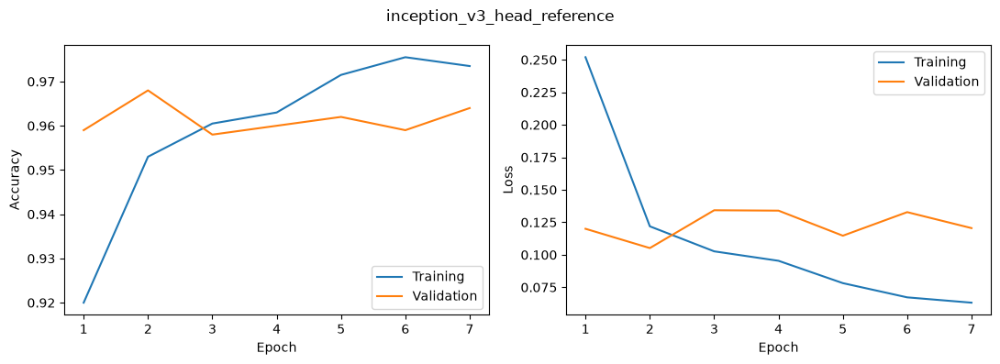

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,reference,128,0.5,0,adam,0.001,15,25,7,2,4.806693,0.105163,0.968,0.9735


In [10]:
results.append(train_heads(features, labels, head_configs['Reference'], NAME))

### Dense width

units_32 Validation: 96.70%, loss: 0.1052


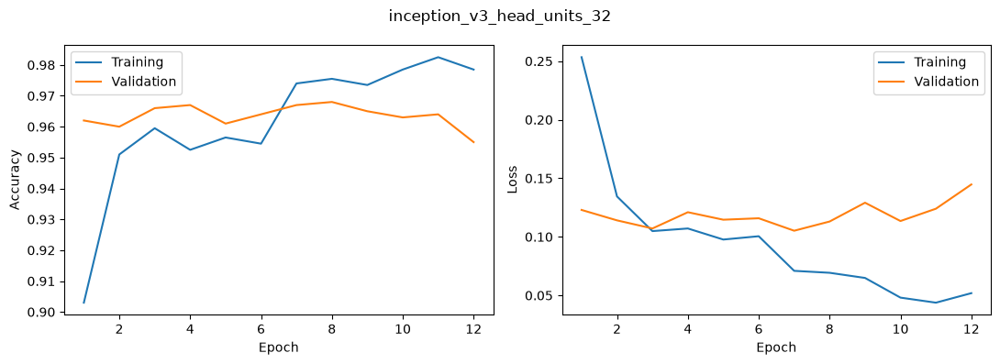

units_256 Validation: 96.40%, loss: 0.1166


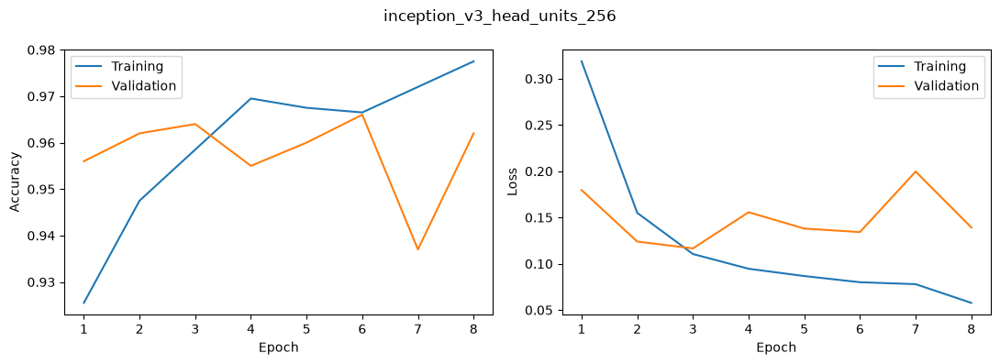

units_512 Validation: 96.30%, loss: 0.1344


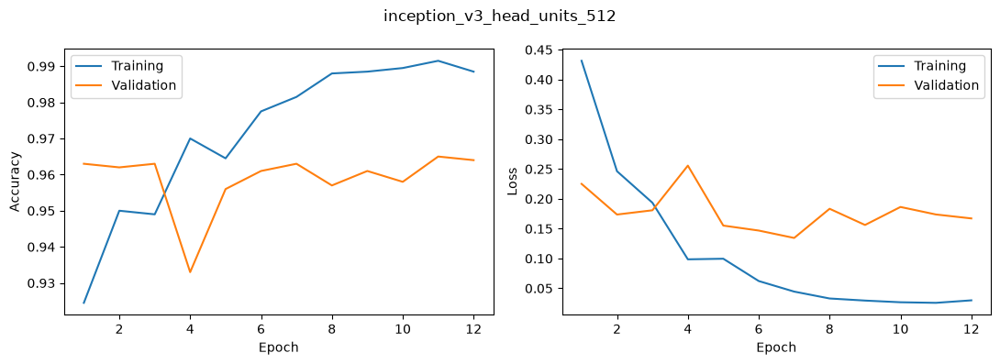

units_1024 Validation: 96.00%, loss: 0.1596


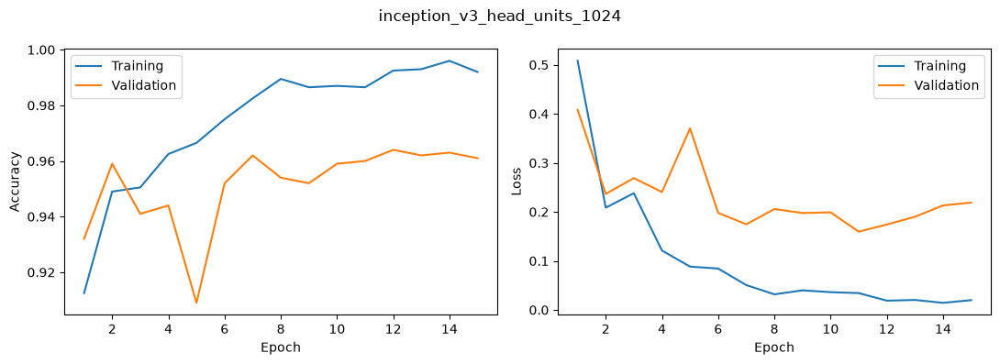

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
1,units_32,32,0.5,0,adam,0.001,15,25,12,7,6.260604,0.105191,0.967,0.9785
2,units_256,256,0.5,0,adam,0.001,15,25,8,3,5.114791,0.116556,0.964,0.9775
3,units_512,512,0.5,0,adam,0.001,15,25,12,7,5.802915,0.134395,0.963,0.9885
4,units_1024,1024,0.5,0,adam,0.001,15,25,15,11,7.136836,0.159593,0.960,0.9920


In [10]:
results.append(train_heads(features, labels, head_configs['Dense width'], NAME))

### Dropout

dropout_0.25 Validation: 96.40%, loss: 0.1096


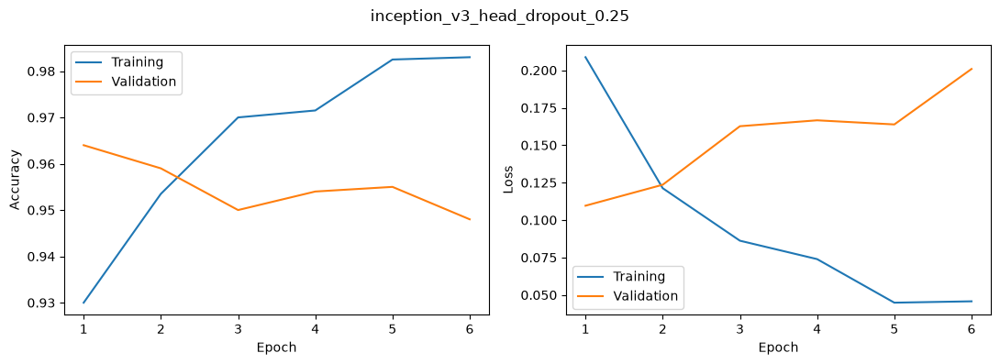

dropout_0.6 Validation: 96.70%, loss: 0.1042


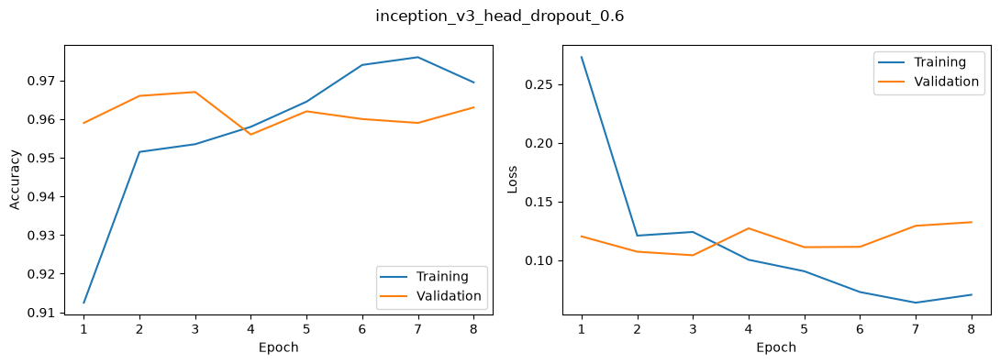

dropout_0.8 Validation: 96.80%, loss: 0.0944


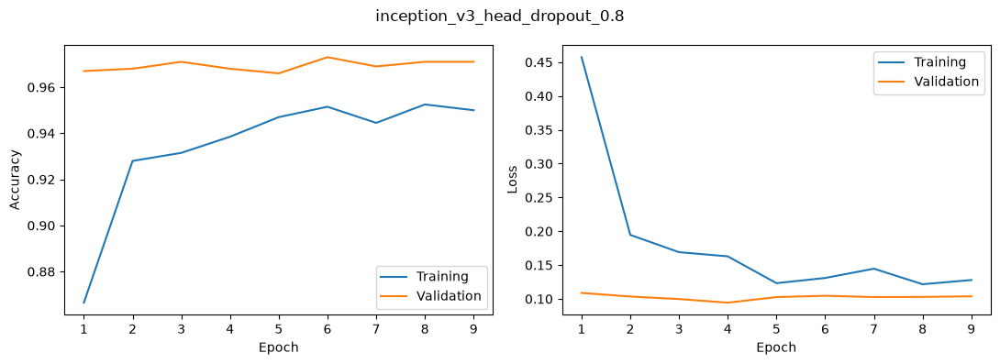

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
5,dropout_0.25,128,0.25,0,adam,0.001,15,25,6,1,3.627139,0.109582,0.964,0.9830
6,dropout_0.6,128,0.60,0,adam,0.001,15,25,8,3,5.491544,0.104213,0.967,0.9695
7,dropout_0.8,128,0.80,0,adam,0.001,15,25,9,4,4.918525,0.094361,0.968,0.9500


In [10]:
results.append(train_heads(features, labels, head_configs['Dropout'], NAME))

### Extra Dense layer

extra_32 Validation: 96.50%, loss: 0.1089


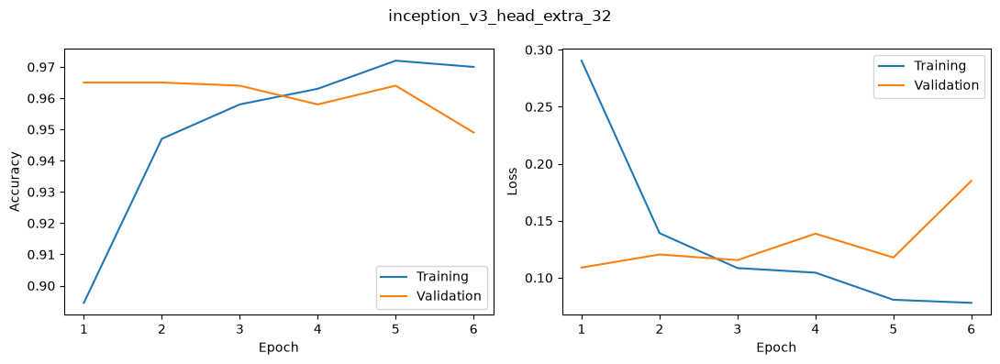

extra_128 Validation: 96.30%, loss: 0.1112


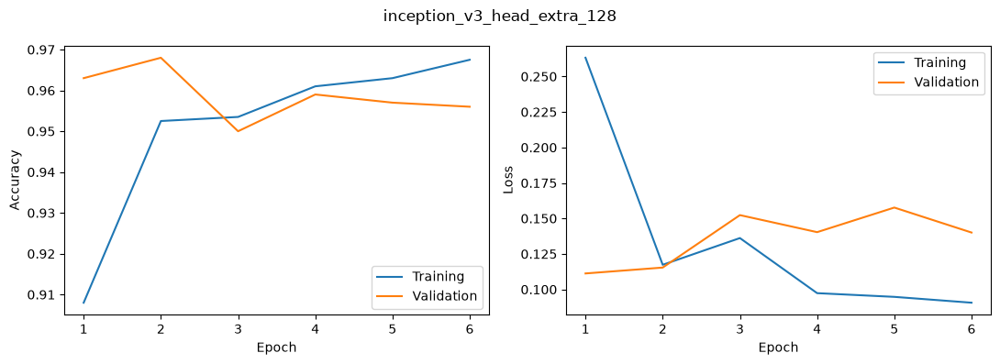

extra_256 Validation: 96.60%, loss: 0.1048


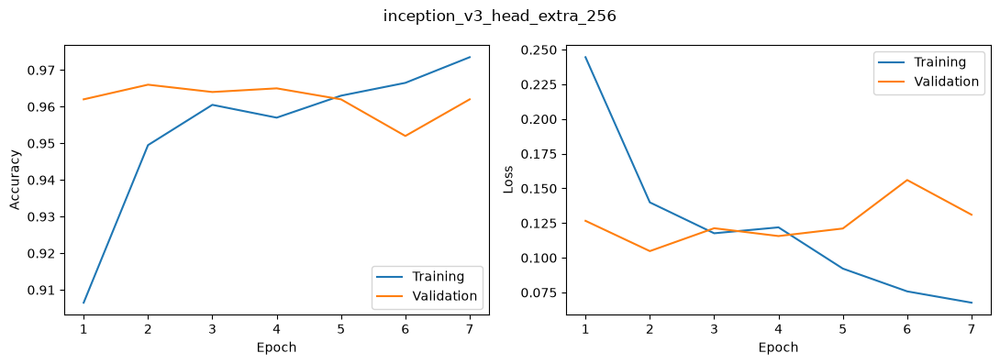

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
8,extra_32,128,0.5,32,adam,0.001,15,25,6,1,4.575758,0.108930,0.965,0.9700
9,extra_128,128,0.5,128,adam,0.001,15,25,6,1,4.680912,0.111244,0.963,0.9675
10,extra_256,128,0.5,256,adam,0.001,15,25,7,2,5.853140,0.104815,0.966,0.9735


In [10]:
results.append(train_heads(features, labels, head_configs['Extra Dense layer'], NAME))

### Epochs

epochs_5 Validation: 96.80%, loss: 0.1052


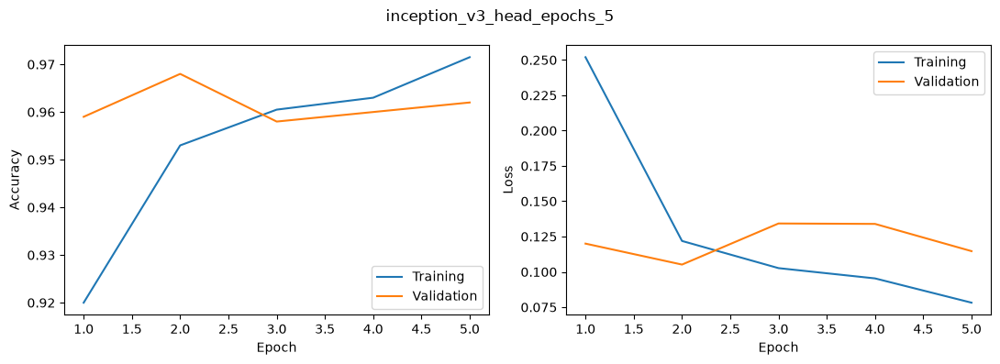

epochs_10 Validation: 96.80%, loss: 0.1052


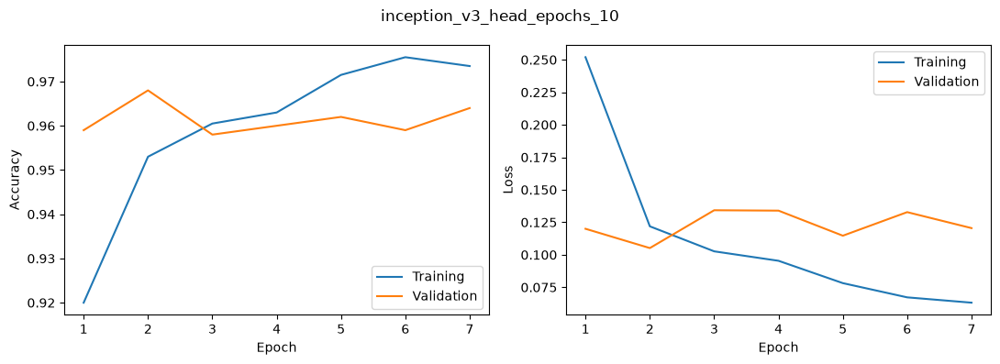

epochs_20 Validation: 96.80%, loss: 0.1052


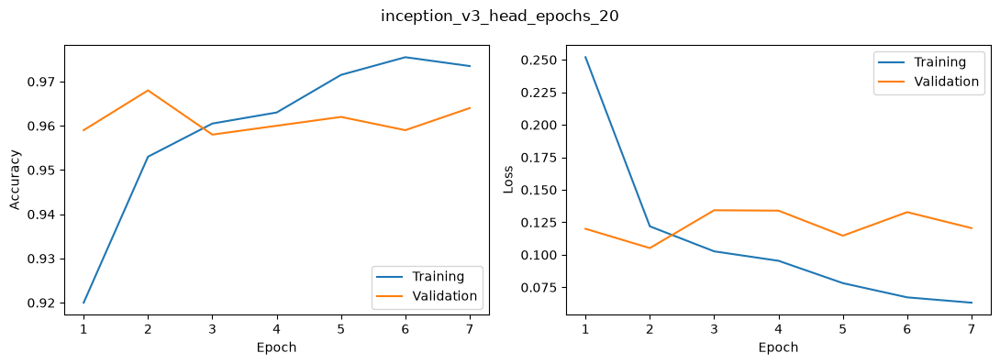

epochs_25 Validation: 96.80%, loss: 0.1052


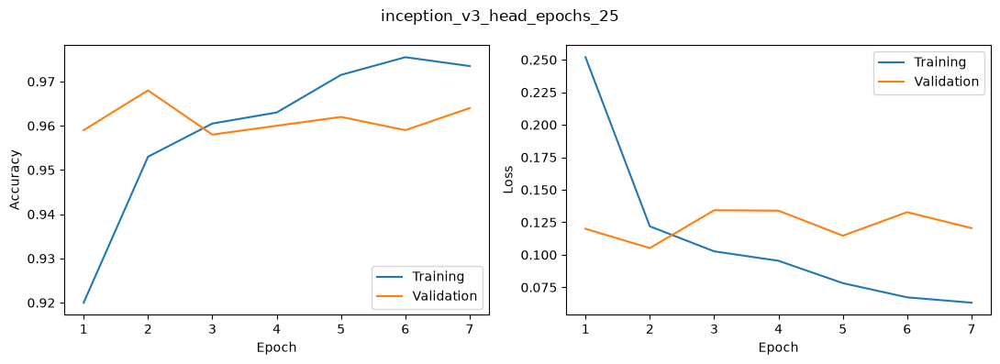

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
11,epochs_5,128,0.5,0,adam,0.001,5,25,5,2,4.487086,0.105163,0.968,0.9715
12,epochs_10,128,0.5,0,adam,0.001,10,25,7,2,5.351639,0.105163,0.968,0.9735
13,epochs_20,128,0.5,0,adam,0.001,20,25,7,2,4.109620,0.105163,0.968,0.9735
14,epochs_25,128,0.5,0,adam,0.001,25,25,7,2,4.040746,0.105163,0.968,0.9735


In [10]:
results.append(train_heads(features, labels, head_configs['Epochs'], NAME))

### Batch size

batch_50 Validation: 97.00%, loss: 0.0991


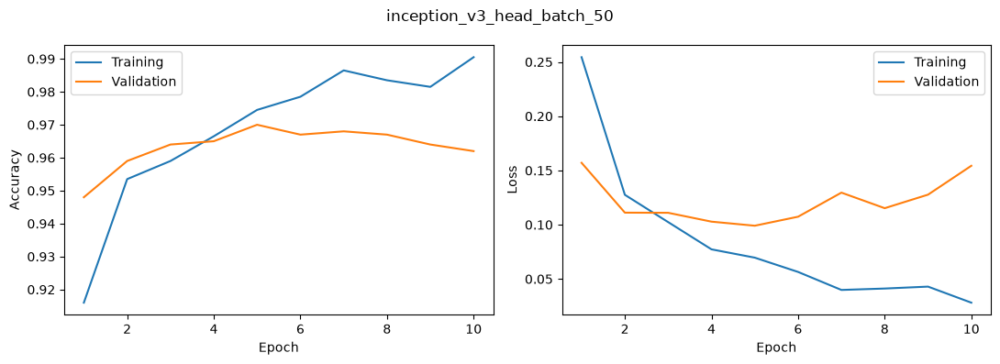

batch_100 Validation: 96.90%, loss: 0.1000


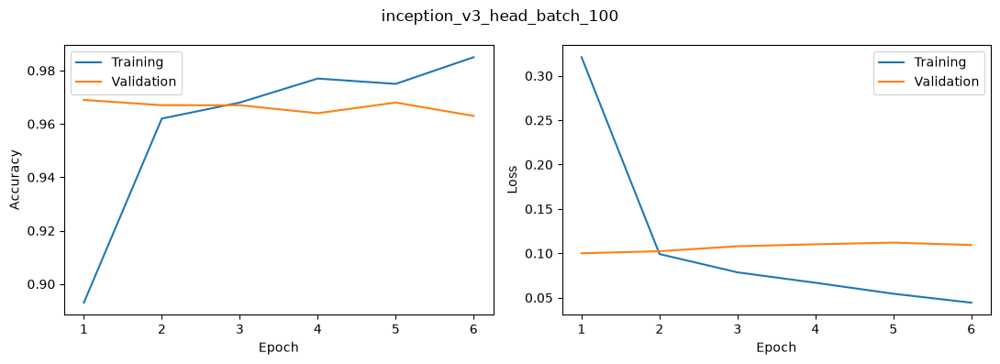

batch_125 Validation: 96.40%, loss: 0.1036


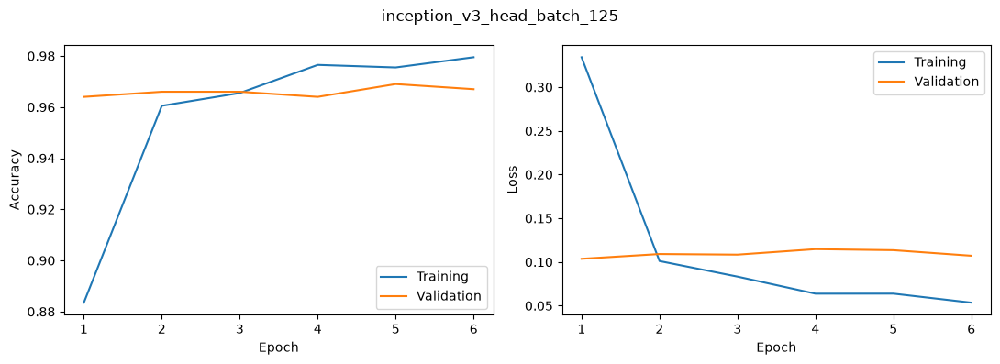

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
15,batch_50,128,0.5,0,adam,0.001,15,50,10,5,4.391542,0.099064,0.970,0.9905
16,batch_100,128,0.5,0,adam,0.001,15,100,6,1,3.369047,0.100021,0.969,0.9850
17,batch_125,128,0.5,0,adam,0.001,15,125,6,1,3.326623,0.103610,0.964,0.9795


In [10]:
results.append(train_heads(features, labels, head_configs['Batch size'], NAME))

### Optimizer

sgd Validation: 96.30%, loss: 0.1032


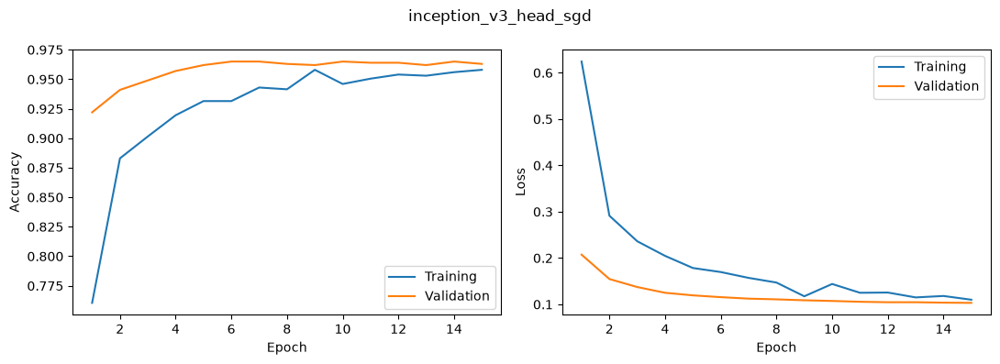

rmsprop Validation: 96.80%, loss: 0.1263


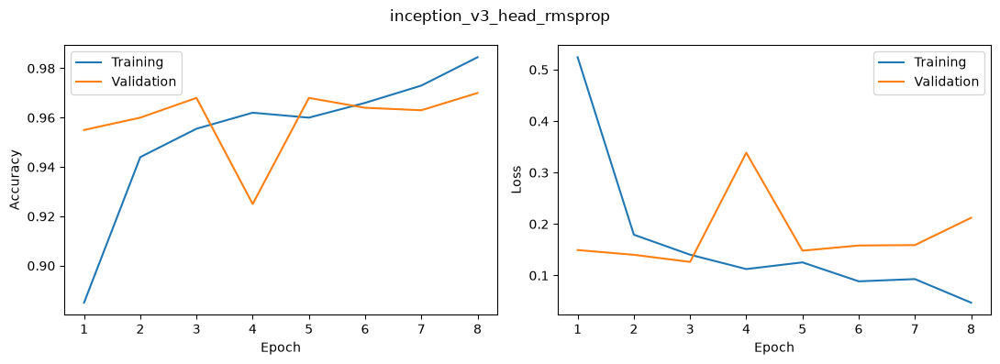

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
18,sgd,128,0.5,0,sgd,0.001,15,25,15,15,6.133529,0.103197,0.963,0.9580
19,rmsprop,128,0.5,0,rmsprop,0.001,15,25,8,3,3.966528,0.126264,0.968,0.9845


In [10]:
results.append(train_heads(features, labels, head_configs['Optimizer'], NAME))

### Learning rate

lr_0.0001 Validation: 96.70%, loss: 0.0956


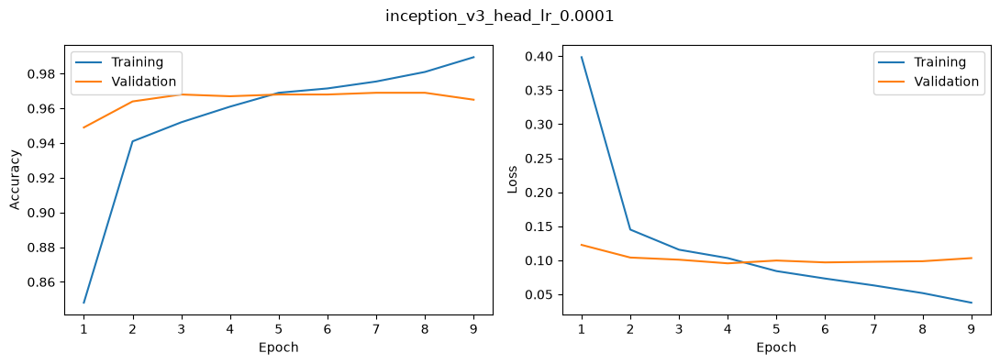

lr_1e-05 Validation: 96.20%, loss: 0.1086


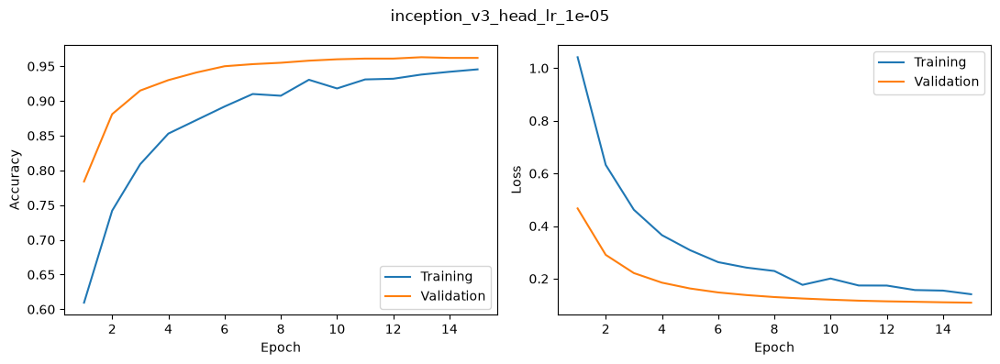

lr_1e-06 Validation: 84.30%, loss: 0.3663


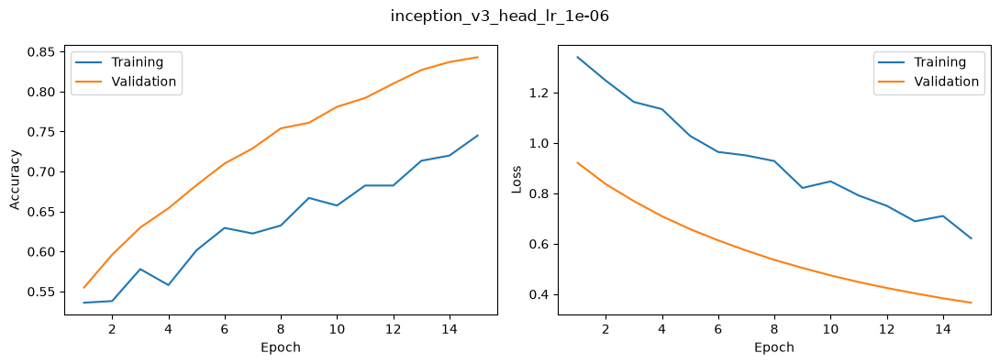

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
20,lr_0.0001,128,0.5,0,adam,0.000100,15,25,9,4,4.659763,0.095555,0.967,0.9895
21,lr_1e-05,128,0.5,0,adam,0.000010,15,25,15,15,5.781536,0.108641,0.962,0.9455
22,lr_1e-06,128,0.5,0,adam,0.000001,15,25,15,15,6.039650,0.366331,0.843,0.7450


In [10]:
results.append(train_heads(features, labels, head_configs['Learning rate'], NAME))

In [10]:
results = pd.concat(results, ignore_index=True)
results.to_csv(f'results/{NAME}_experiments.csv', index=False)
display(results)

,name,units,dropout,extra_units,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,seconds,val_loss,val_accuracy,train_accuracy
0,reference,128,0.50,0,adam,0.001000,15,25,7,2,4.806693,0.105163,0.968,0.9735
1,units_32,32,0.50,0,adam,0.001000,15,25,12,7,6.260604,0.105191,0.967,0.9785
2,units_256,256,0.50,0,adam,0.001000,15,25,8,3,5.114791,0.116556,0.964,0.9775
3,units_512,512,0.50,0,adam,0.001000,15,25,12,7,5.802915,0.134395,0.963,0.9885
4,units_1024,1024,0.50,0,adam,0.001000,15,25,15,11,7.136836,0.159593,0.960,0.9920
5,dropout_0.25,128,0.25,0,adam,0.001000,15,25,6,1,3.627139,0.109582,0.964,0.9830
6,dropout_0.6,128,0.60,0,adam,0.001000,15,25,8,3,5.491544,0.104213,0.967,0.9695
7,dropout_0.8,128,0.80,0,adam,0.001000,15,25,9,4,4.918525,0.094361,0.968,0.9500
8,extra_32,128,0.50,32,adam,0.001000,15,25,6,1,4.575758,0.108930,0.965,0.9700
9,extra_128,128,0.50,128,adam,0.001000,15,25,6,1,4.680912,0.111244,0.963,0.9675


In [11]:
model, head, best, config = assemble_model(base, results, NAME)

In [12]:
model_dir = DATA_ROOT / 'models' / 'lab9'
start_file = model_dir / f'{NAME}_start.keras'
best_file = model_dir / f'{NAME}.keras'
model.save(start_file)
# Compare the tuned head with the lab 8 checkpoint before fine-tuning.
transfer = load_bundle(f'../lab8/models/{NAME}')
transfer.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
transfer_loss, transfer_accuracy = transfer.evaluate(validation_generator, verbose=0)
head_loss, head_accuracy = model.evaluate(validation_generator, verbose=0)
print('Lab 8 validation:', transfer_loss, transfer_accuracy)
print('Tuned head validation:', head_loss, head_accuracy)
del transfer

Lab 8 validation: 0.09436109662055969 0.9679999947547913
Tuned head validation: 0.09436109662055969 0.9679999947547913


## Fine tuning

Found 2000 images belonging to 2 classes.


{'name': 'adam_0.001', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 5, 'batch_size': 25} Trainable weights: 6332673
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 24s - 304ms/step - accuracy: 0.9300 - loss: 0.3857 - val_accuracy: 0.9400 - val_loss: 0.1596


Epoch 2/5


80/80 - 5s - 68ms/step - accuracy: 0.9510 - loss: 0.1552 - val_accuracy: 0.9640 - val_loss: 0.1375


... (2 outputs left out)

Epoch 4/5


80/80 - 5s - 57ms/step - accuracy: 0.9745 - loss: 0.0843 - val_accuracy: 0.9630 - val_loss: 0.4067


Epoch 5/5


80/80 - 5s - 57ms/step - accuracy: 0.9735 - loss: 0.0955 - val_accuracy: 0.9650 - val_loss: 1.0807


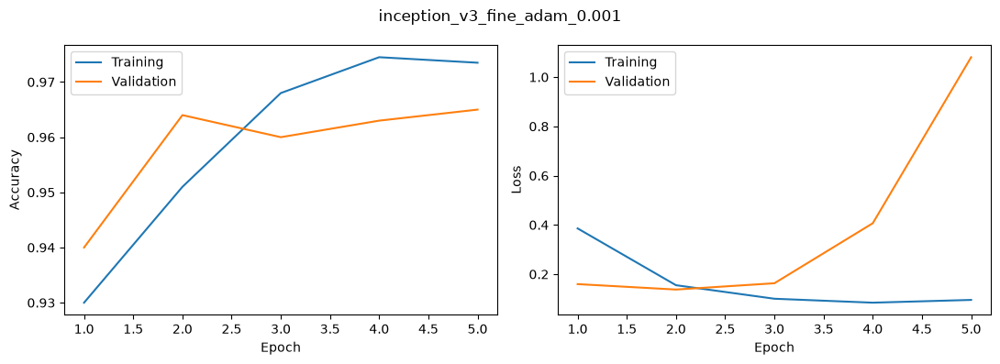

Found 2000 images belonging to 2 classes.


{'name': 'adam_0.0001', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 0.0001, 'epochs': 5, 'batch_size': 25} Trainable weights: 6332673
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 25s - 313ms/step - accuracy: 0.9595 - loss: 0.1361 - val_accuracy: 0.9670 - val_loss: 0.1020


Epoch 2/5


80/80 - 5s - 57ms/step - accuracy: 0.9795 - loss: 0.0691 - val_accuracy: 0.9710 - val_loss: 0.1468


Epoch 3/5


80/80 - 5s - 59ms/step - accuracy: 0.9905 - loss: 0.0414 - val_accuracy: 0.9670 - val_loss: 0.1969


Epoch 4/5


80/80 - 5s - 61ms/step - accuracy: 0.9935 - loss: 0.0283 - val_accuracy: 0.9580 - val_loss: 0.3025


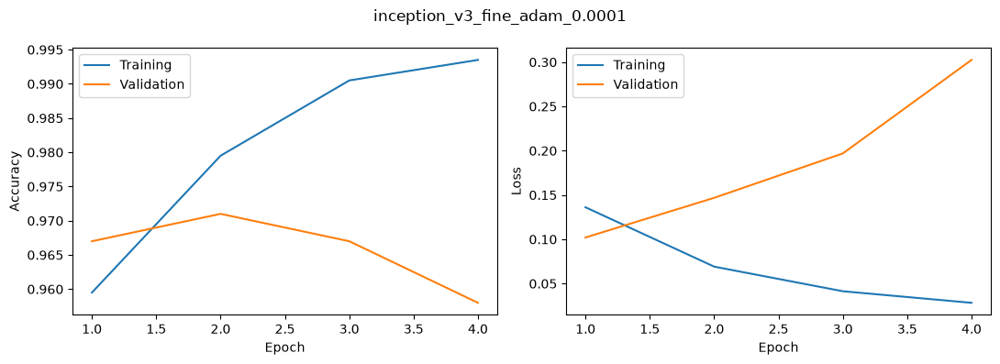

Found 2000 images belonging to 2 classes.


{'name': 'adam_1e-05', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 6332673
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 23s - 288ms/step - accuracy: 0.9575 - loss: 0.1147 - val_accuracy: 0.9700 - val_loss: 0.1025


Epoch 2/5


80/80 - 5s - 57ms/step - accuracy: 0.9750 - loss: 0.0939 - val_accuracy: 0.9690 - val_loss: 0.1127


Epoch 3/5


80/80 - 6s - 75ms/step - accuracy: 0.9720 - loss: 0.0840 - val_accuracy: 0.9690 - val_loss: 0.1160


Epoch 4/5


80/80 - 5s - 65ms/step - accuracy: 0.9795 - loss: 0.0656 - val_accuracy: 0.9690 - val_loss: 0.1302


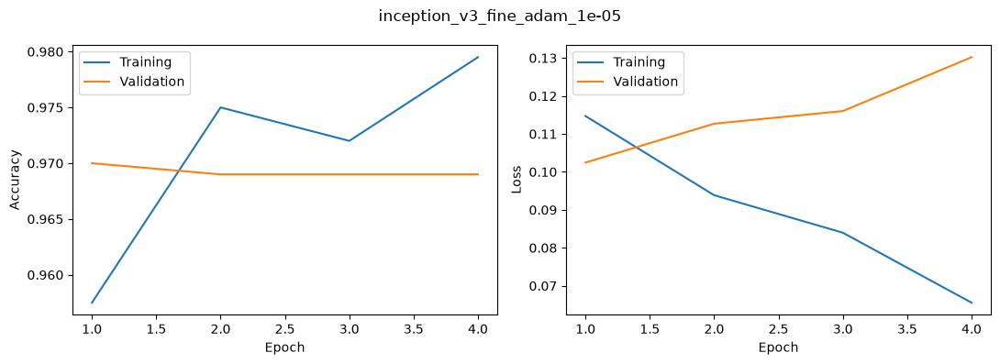

Found 2000 images belonging to 2 classes.


{'name': 'adam_1e-06', 'blocks': 1, 'optimizer': 'adam', 'learning_rate': 1e-06, 'epochs': 5, 'batch_size': 25} Trainable weights: 6332673
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 27s - 336ms/step - accuracy: 0.9550 - loss: 0.1252 - val_accuracy: 0.9680 - val_loss: 0.0944


Epoch 2/5


80/80 - 6s - 72ms/step - accuracy: 0.9575 - loss: 0.1223 - val_accuracy: 0.9680 - val_loss: 0.0948


Epoch 3/5


80/80 - 5s - 69ms/step - accuracy: 0.9565 - loss: 0.1264 - val_accuracy: 0.9680 - val_loss: 0.0950


Epoch 4/5


80/80 - 5s - 61ms/step - accuracy: 0.9640 - loss: 0.1129 - val_accuracy: 0.9700 - val_loss: 0.0953


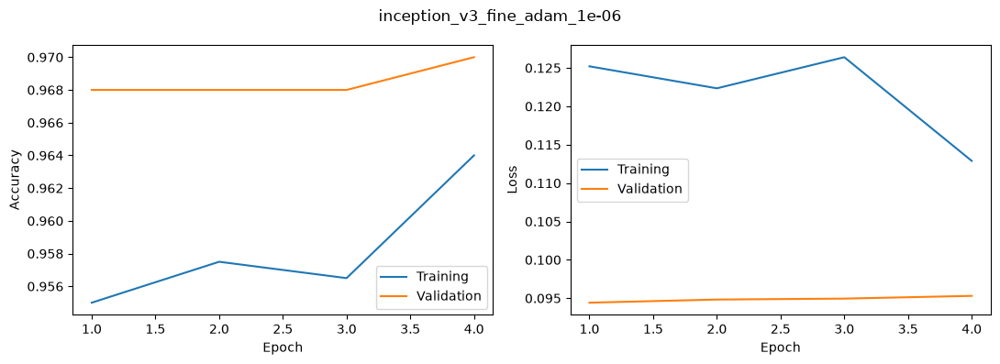

Found 2000 images belonging to 2 classes.


{'name': 'sgd', 'blocks': 1, 'optimizer': 'sgd', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 6332673
Epoch 1/5


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


80/80 - 24s - 304ms/step - accuracy: 0.9525 - loss: 0.1272 - val_accuracy: 0.9680 - val_loss: 0.0944


Epoch 2/5


80/80 - 6s - 81ms/step - accuracy: 0.9565 - loss: 0.1282 - val_accuracy: 0.9680 - val_loss: 0.0944


... (2 outputs left out)

Epoch 4/5


80/80 - 5s - 58ms/step - accuracy: 0.9570 - loss: 0.1285 - val_accuracy: 0.9680 - val_loss: 0.0943


Epoch 5/5


80/80 - 5s - 67ms/step - accuracy: 0.9550 - loss: 0.1190 - val_accuracy: 0.9680 - val_loss: 0.0943


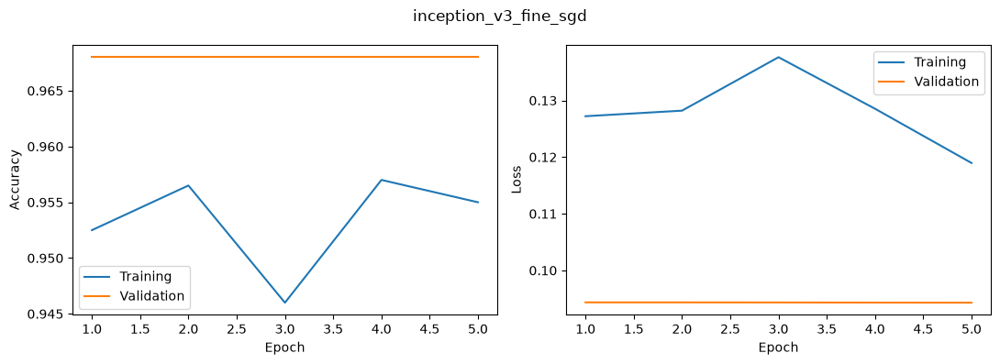

Found 2000 images belonging to 2 classes.


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


{'name': 'rmsprop', 'blocks': 1, 'optimizer': 'rmsprop', 'learning_rate': 1e-05, 'epochs': 5, 'batch_size': 25} Trainable weights: 6332673
Epoch 1/5


80/80 - 26s - 323ms/step - accuracy: 0.9570 - loss: 0.1161 - val_accuracy: 0.9700 - val_loss: 0.1023


Epoch 2/5


80/80 - 4s - 54ms/step - accuracy: 0.9695 - loss: 0.0988 - val_accuracy: 0.9690 - val_loss: 0.1146


Epoch 3/5


80/80 - 4s - 56ms/step - accuracy: 0.9715 - loss: 0.0959 - val_accuracy: 0.9680 - val_loss: 0.1196


Epoch 4/5


80/80 - 4s - 54ms/step - accuracy: 0.9740 - loss: 0.0772 - val_accuracy: 0.9700 - val_loss: 0.1311


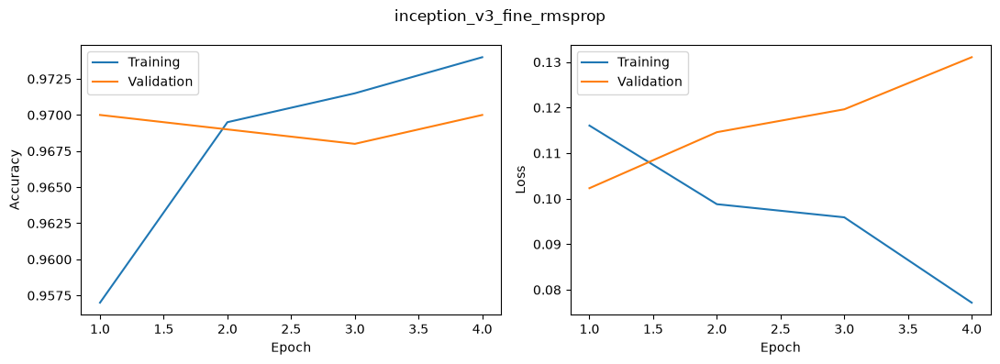

Found 2000 images belonging to 2 classes.


/home/surikadt/Univ/7s/aml/.venv/lib64/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_21', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


{'name': 'two_blocks', 'blocks': 2, 'optimizer': 'adam', 'learning_rate': 1e-05, 'epochs': 10, 'batch_size': 50} Trainable weights: 11370753
Epoch 1/10


40/40 - 32s - 812ms/step - accuracy: 0.9595 - loss: 0.1292 - val_accuracy: 0.9730 - val_loss: 0.0989


Epoch 2/10


40/40 - 4s - 107ms/step - accuracy: 0.9740 - loss: 0.0768 - val_accuracy: 0.9720 - val_loss: 0.1069


Epoch 3/10


40/40 - 4s - 105ms/step - accuracy: 0.9865 - loss: 0.0543 - val_accuracy: 0.9750 - val_loss: 0.1264


Epoch 4/10


40/40 - 4s - 109ms/step - accuracy: 0.9865 - loss: 0.0424 - val_accuracy: 0.9720 - val_loss: 0.1497


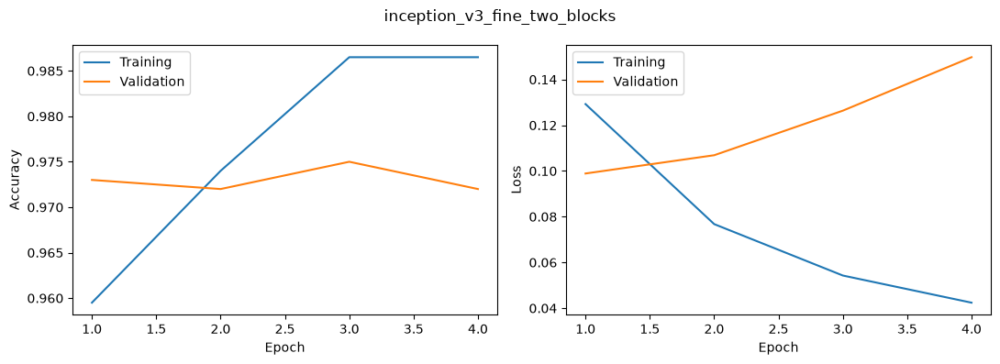

,name,blocks,optimizer,learning_rate,epochs,batch_size,epochs_run,best_epoch,val_loss,val_accuracy,seconds
0,adam_0.001,1,adam,0.001000,5,25,5,2,0.137523,0.964,46.486256
1,adam_0.0001,1,adam,0.000100,5,25,4,1,0.102036,0.967,41.704906
2,adam_1e-05,1,adam,0.000010,5,25,4,1,0.102464,0.970,41.240021
3,adam_1e-06,1,adam,0.000001,5,25,4,1,0.094420,0.968,45.114956
4,sgd,1,sgd,0.000010,5,25,5,5,0.094301,0.968,47.988754
5,rmsprop,1,rmsprop,0.000010,5,25,4,1,0.102303,0.970,40.911500
6,two_blocks,2,adam,0.000010,10,50,4,1,0.098892,0.973,47.283306


In [15]:
finetune_results, best_config_ft = fine_tune(start_file, fine_configs, validation_generator, preprocess_input, NAME)

## Results

In [16]:
# Test data are evaluated after choosing the fine-tuning checkpoint on validation loss.
model = keras.models.load_model(best_file)
base = model.get_layer(NAME)
head = next(layer for layer in model.layers if isinstance(layer, keras.Sequential))
fine_loss, fine_accuracy = model.evaluate(test_generator, verbose=0)
result = {'model': NAME, 'fine_experiment': best_config_ft['name'],
          'val_loss': float(finetune_results['val_loss'].min()),
          'val_accuracy': float(finetune_results.sort_values('val_loss').iloc[0]['val_accuracy']),
          'test_loss': fine_loss, 'test_accuracy': fine_accuracy,
          'head_experiment': str(best['name'])}
previous = json.loads(Path(f'../lab8/results/{NAME}_metrics.json').read_text())
comparison = pd.DataFrame([{'stage': 'transfer', **previous}, {'stage': 'fine_tuning', **result}])
comparison.to_csv(f'results/{NAME}_comparison.csv', index=False)
display(comparison)
Path(f'results/{NAME}_metrics.json').write_text(json.dumps(result, indent=2))

,stage,model,experiment,val_loss,val_accuracy,test_loss,test_accuracy,parameters,fine_experiment,head_experiment
0,transfer,inception_v3,dropout_0.8,0.094361,0.968,0.094902,0.963,22065185.0,NaN,NaN
1,fine_tuning,inception_v3,NaN,0.094301,0.968,0.094802,0.963,NaN,sgd,dropout_0.8


241

## Saving

In [17]:
save_bundle(model, base, head, f'models/{NAME}', config)

## New images

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,0.018371,cat,True
1,cat_02.jpg,cat,0.499192,cat,True
2,cat_03.jpg,cat,0.780235,dog,False
3,cat_04.jpg,cat,0.232963,cat,True
4,cat_05.jpg,cat,0.585877,dog,False
5,dog_01.jpg,dog,0.999318,dog,True
6,dog_02.jpg,dog,0.863522,dog,True
7,dog_03.jpg,dog,0.728138,dog,True
8,dog_04.jpg,dog,0.800279,dog,True
9,dog_05.jpg,dog,0.584360,dog,True


External accuracy: 80.00%


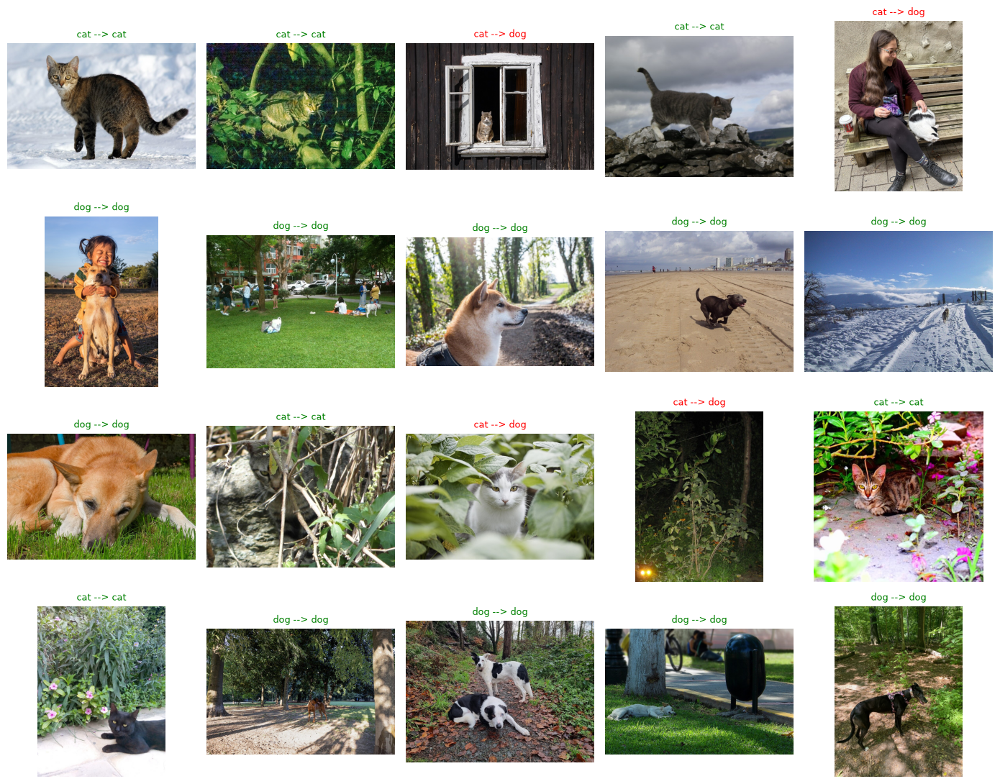

In [19]:
new_results = predict_images(model, images, manifest, preprocess_input, NAME)

In [21]:
previous_external = pd.read_csv(f'../lab8/results/{NAME}_external.csv')
external_comparison = previous_external[['file', 'class', 'prediction', 'correct']].merge(
    new_results[['file', 'prediction', 'correct']], on='file', suffixes=('_transfer', '_fine'))
display(external_comparison)
external_comparison.to_csv(f'results/{NAME}_external_comparison.csv', index=False)
print('Transfer:', previous_external['correct'].mean(), 'Fine tuning:', new_results['correct'].mean())

,file,class,prediction_transfer,correct_transfer,prediction_fine,correct_fine
0,cat_01.jpg,cat,cat,True,cat,True
1,cat_02.jpg,cat,cat,True,cat,True
2,cat_03.jpg,cat,dog,False,dog,False
3,cat_04.jpg,cat,cat,True,cat,True
4,cat_05.jpg,cat,dog,False,dog,False
5,dog_01.jpg,dog,dog,True,dog,True
6,dog_02.jpg,dog,dog,True,dog,True
7,dog_03.jpg,dog,dog,True,dog,True
8,dog_04.jpg,dog,dog,True,dog,True
9,dog_05.jpg,dog,dog,True,dog,True


Transfer: 0.8 Fine tuning: 0.8


In [ ]:
del model, base, head
keras.backend.clear_session()

# Comparison

,model,stage,val_accuracy,test_accuracy,external_accuracy
0,cnn,from_scratch,0.753,0.777,0.45
1,vgg16,transfer,0.967,0.957,0.70
2,resnet50,transfer,0.979,0.966,0.75
3,inception_v3,transfer,0.968,0.963,0.80
4,vgg16,fine_tuning,0.978,0.959,0.75
5,resnet50,fine_tuning,0.980,0.968,0.75
6,inception_v3,fine_tuning,0.968,0.963,0.80


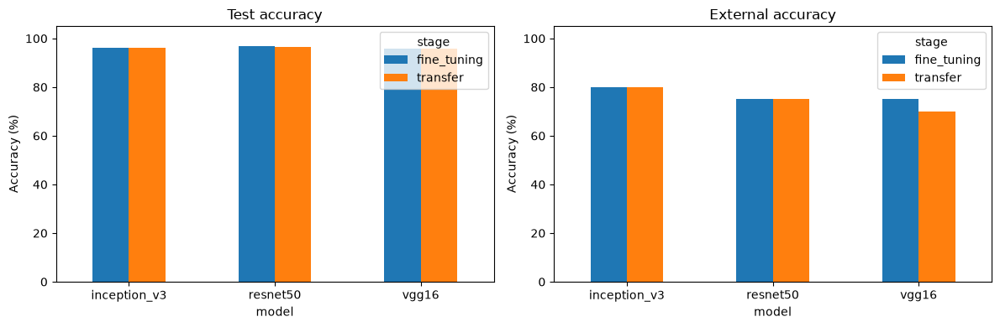

In [22]:
rows = []
cnn = json.loads(Path('../lab7/results/cats_metrics.json').read_text())
cnn_external = pd.read_csv('../lab7/results/cats_external.csv')
rows.append({'model': 'cnn', 'stage': 'from_scratch', 'val_accuracy': cnn['val_accuracy'],
             'test_accuracy': cnn['test_accuracy'], 'external_accuracy': cnn_external['correct'].mean()})
for stage, folder in [('transfer', '../lab8'), ('fine_tuning', '.')]:
    for name in ['vgg16', 'resnet50', 'inception_v3']:
        metrics = json.loads((Path(folder) / 'results' / f'{name}_metrics.json').read_text())
        external = pd.read_csv(Path(folder) / 'results' / f'{name}_external.csv')
        rows.append({'model': name, 'stage': stage, 'val_accuracy': metrics['val_accuracy'],
                     'test_accuracy': metrics['test_accuracy'],
                     'external_accuracy': external['correct'].mean()})
comparison = pd.DataFrame(rows)
comparison.to_csv('results/comparison.csv', index=False)
display(comparison)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axs, ['test_accuracy', 'external_accuracy']):
    table = comparison[comparison['model'] != 'cnn'].pivot(index='model', columns='stage', values=metric)
    (table * 100).plot.bar(ax=ax, rot=0)
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(metric.replace('_', ' ').capitalize())
    ax.set_ylim(0, 105)
plt.tight_layout()
fig.savefig('results/comparison.png', dpi=150)
plt.show()


# Summary

## VGG16

Для vgg16 спочатку порівняно 23 конфігурації класифікатора на заморожених ознаках: ширину Dense, Dropout, додатковий Dense, оптимізатор, швидкість навчання, розмір пакета та межу епох. Це послідовні зміни окремих налаштувань, а не повний перебір усіх комбінацій. Найменші валідаційні втрати отримано для **dropout_0.8**.

Потім кожен дослід тонкого налаштування починався з тих самих навчених ваг класифікатора. Розморожено один або два кінцеві згорткові блоки; BatchNormalization залишено замороженим, базова мережа викликається з training=False. Після зміни trainable модель перекомпільовано. Вхід, підготовка даних та поділ залишилися такими самими, як у лабораторній 8.

| Experiment | Blocks | Learning rate | Validation accuracy | Validation loss | Best epoch |
|---|---:|---:|---:|---:|---:|
| adam_0.001 | 1 | 0.001 | 50.10% | 0.6931 | 3 |
| adam_0.0001 | 1 | 0.0001 | 96.50% | 0.0785 | 3 |
| adam_1e-05 | 1 | 1e-05 | 97.40% | 0.0634 | 3 |
| adam_1e-06 | 1 | 1e-06 | 96.90% | 0.0662 | 4 |
| sgd | 1 | 1e-05 | 96.80% | 0.0692 | 3 |
| rmsprop | 1 | 1e-05 | 97.30% | 0.0632 | 3 |
| two_blocks | 2 | 1e-05 | 97.80% | 0.0556 | 3 |

За валідаційними втратами обрано **two_blocks**. Точність валідації - **97.80%**, тестова - **95.90%**; для перенесення без тонкого налаштування було **95.70%**. Зміна тестової точності становила **+0.20 відсоткового пункта**. Графіки показують перебіг перенавчання та реакцію на швидкість навчання; занадто велика швидкість може погіршувати попередньо навчені ознаки.

На тих самих 20 зовнішніх фото точність змінилася з **70.00%** до **75.00%**. Одне фото тут змінює результат на 5 відсоткових пунктів, тому ці числа не замінюють оцінку на повній тестовій вибірці. Краща валідація не гарантує покращення кожного зовнішнього прикладу. Збережені ваги класифікатора та змінених згорткових шарів можна завантажувати без повторного навчання.

## ResNet50

Для resnet50 спочатку порівняно 23 конфігурації класифікатора на заморожених ознаках: ширину Dense, Dropout, додатковий Dense, оптимізатор, швидкість навчання, розмір пакета та межу епох. Це послідовні зміни окремих налаштувань, а не повний перебір усіх комбінацій. Найменші валідаційні втрати отримано для **dropout_0.8**.

Потім кожен дослід тонкого налаштування починався з тих самих навчених ваг класифікатора. Розморожено один або два кінцеві згорткові блоки; BatchNormalization залишено замороженим, базова мережа викликається з training=False. Після зміни trainable модель перекомпільовано. Вхід, підготовка даних та поділ залишилися такими самими, як у лабораторній 8.

| Experiment | Blocks | Learning rate | Validation accuracy | Validation loss | Best epoch |
|---|---:|---:|---:|---:|---:|
| adam_0.001 | 1 | 0.001 | 97.10% | 0.0549 | 2 |
| adam_0.0001 | 1 | 0.0001 | 97.90% | 0.0509 | 3 |
| adam_1e-05 | 1 | 1e-05 | 98.00% | 0.0503 | 1 |
| adam_1e-06 | 1 | 1e-06 | 98.00% | 0.0501 | 4 |
| sgd | 1 | 1e-05 | 98.00% | 0.0511 | 5 |
| rmsprop | 1 | 1e-05 | 98.10% | 0.0522 | 1 |
| two_blocks | 2 | 1e-05 | 98.00% | 0.0514 | 1 |

За валідаційними втратами обрано **adam_1e-06**. Точність валідації - **98.00%**, тестова - **96.80%**; для перенесення без тонкого налаштування було **96.60%**. Зміна тестової точності становила **+0.20 відсоткового пункта**. Графіки показують перебіг перенавчання та реакцію на швидкість навчання; занадто велика швидкість може погіршувати попередньо навчені ознаки.

На тих самих 20 зовнішніх фото точність змінилася з **75.00%** до **75.00%**. Одне фото тут змінює результат на 5 відсоткових пунктів, тому ці числа не замінюють оцінку на повній тестовій вибірці. Краща валідація не гарантує покращення кожного зовнішнього прикладу. Збережені ваги класифікатора та змінених згорткових шарів можна завантажувати без повторного навчання.

## InceptionV3

Для inception_v3 спочатку порівняно 23 конфігурації класифікатора на заморожених ознаках: ширину Dense, Dropout, додатковий Dense, оптимізатор, швидкість навчання, розмір пакета та межу епох. Це послідовні зміни окремих налаштувань, а не повний перебір усіх комбінацій. Найменші валідаційні втрати отримано для **dropout_0.8**.

Потім кожен дослід тонкого налаштування починався з тих самих навчених ваг класифікатора. Розморожено один або два кінцеві згорткові блоки; BatchNormalization залишено замороженим, базова мережа викликається з training=False. Після зміни trainable модель перекомпільовано. Вхід, підготовка даних та поділ залишилися такими самими, як у лабораторній 8.

| Experiment | Blocks | Learning rate | Validation accuracy | Validation loss | Best epoch |
|---|---:|---:|---:|---:|---:|
| adam_0.001 | 1 | 0.001 | 96.40% | 0.1375 | 2 |
| adam_0.0001 | 1 | 0.0001 | 96.70% | 0.1020 | 1 |
| adam_1e-05 | 1 | 1e-05 | 97.00% | 0.1025 | 1 |
| adam_1e-06 | 1 | 1e-06 | 96.80% | 0.0944 | 1 |
| sgd | 1 | 1e-05 | 96.80% | 0.0943 | 5 |
| rmsprop | 1 | 1e-05 | 97.00% | 0.1023 | 1 |
| two_blocks | 2 | 1e-05 | 97.30% | 0.0989 | 1 |

За валідаційними втратами обрано **sgd**. Точність валідації - **96.80%**, тестова - **96.30%**; для перенесення без тонкого налаштування було **96.30%**. Зміна тестової точності становила **+0.00 відсоткового пункта**. Графіки показують перебіг перенавчання та реакцію на швидкість навчання; занадто велика швидкість може погіршувати попередньо навчені ознаки.

На тих самих 20 зовнішніх фото точність змінилася з **80.00%** до **80.00%**. Одне фото тут змінює результат на 5 відсоткових пунктів, тому ці числа не замінюють оцінку на повній тестовій вибірці. Краща валідація не гарантує покращення кожного зовнішнього прикладу. Збережені ваги класифікатора та змінених згорткових шарів можна завантажувати без повторного навчання.